# Household Electricity Demand Forecasting
This notebook contains the full analysis (Parts 1-8 of the assignment): downloading
and cleaning the UCI Household Electric Power Consumption dataset, exploratory
analysis and stationarity testing, then 24-hour-ahead forecasts with benchmark
models, SARIMA/SARIMAX, XGBoost and the Chronos foundation model, and a final
comparison of all models.

## Step 1: Setup
Clone the project repository from GitHub and download the dataset.
The raw data (127 MB) is too large for GitHub, so it is downloaded by
`src/download_data.py`. This keeps the analysis reproducible.

In [26]:
# Clone the project repository into Colab (skip if already cloned)
import os

REPO_DIR = "/content/household-electricity-forecast"

if not os.path.exists(REPO_DIR):
    !git clone https://github.com/Navyanalli/household-electricity-forecast.git {REPO_DIR}
    print("Repository cloned")
else:
    print("Repository already present - clone skipped")

Repository already present - clone skipped


In [28]:
# Move into the project folder (absolute path, safe to re-run)
os.chdir(REPO_DIR)

print("Current folder:", os.getcwd())
print("Contents:", sorted(os.listdir()))
print("inside project folder")

Current folder: /content/household-electricity-forecast
Contents: ['.git', '.gitignore', 'README.md', 'data', 'notebooks', 'requirements.txt', 'results', 'src']
inside project folder


In [27]:
# Download and unzip the dataset into data/
!python src/download_data.py

# Check: the data file exists and has the expected size (~127 MB)
data_path = "data/household_power_consumption.txt"
if os.path.exists(data_path):
    size_mb = os.path.getsize(data_path) / 1e6
    print(f"Data file ready: {data_path} ({size_mb:.1f} MB)")
else:
    print("ERROR: data file not found - download failed")

Data already present: /content/household-electricity-forecast/data/household_power_consumption.txt
Data file ready: data/household_power_consumption.txt (133.0 MB)


## Step 2: Load the data
The raw file is semicolon-separated, with one row per minute
(16 Dec 2006 – 26 Nov 2010). Missing values are recorded as "?",
so they are converted to NaN while loading.

In [29]:
# Core libraries for data handling and plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("libraries imported")
print("pandas version:", pd.__version__)

libraries imported
pandas version: 2.2.3


In [30]:
# Read the raw minute-level data; "?" marks missing readings
df_raw = pd.read_csv(
    data_path,
    sep=";",
    na_values="?",
    low_memory=False
)

print("data loaded")
print("Shape (rows, columns):", df_raw.shape)

data loaded
Shape (rows, columns): (2075259, 9)


In [31]:
# Show the first rows and the column data types
print("first 5 rows")
display(df_raw.head())

print("\nColumn data types:")
print(df_raw.dtypes)

first 5 rows


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0



Column data types:
Date                      object
Time                      object
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object


## Step 3: Clean the data
The separate `Date` and `Time` text columns are combined into a single
datetime index, so pandas can treat the data as a time series.
Missing values are then counted to decide how to handle them.

In [32]:
# Combine Date and Time into one datetime column (day comes first: dd/mm/yyyy)
df = df_raw.copy()
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

# Use Datetime as the index and drop the old text columns
df = df.set_index("Datetime").drop(columns=["Date", "Time"])

print("datetime index created")
print("Start:", df.index.min())
print("End:  ", df.index.max())

datetime index created
Start: 2006-12-16 17:24:00
End:   2010-11-26 21:02:00


In [33]:
# Check for duplicate timestamps and that readings are 1 minute apart
n_duplicates = df.index.duplicated().sum()
step_counts = df.index.to_series().diff().value_counts().head()

print("timestamp check")
print("Duplicate timestamps:", n_duplicates)
print("Time gaps between readings:")
print(step_counts)

timestamp check
Duplicate timestamps: 0
Time gaps between readings:
Datetime
0 days 00:01:00    2075258
Name: count, dtype: int64


In [34]:
# Number and percentage of missing values in each column
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

print("missing value summary")
print(missing)

missing value summary
                       missing_count  missing_percent
Global_active_power            25979             1.25
Global_reactive_power          25979             1.25
Voltage                        25979             1.25
Global_intensity               25979             1.25
Sub_metering_1                 25979             1.25
Sub_metering_2                 25979             1.25
Sub_metering_3                 25979             1.25


In [35]:
# Check whether missing values occur in all columns at the same time
rows_all_missing = df.isna().all(axis=1).sum()
rows_any_missing = df.isna().any(axis=1).sum()

print("row-level missing check")
print("Rows with ALL columns missing:", rows_all_missing)
print("Rows with ANY column missing: ", rows_any_missing)

row-level missing check
Rows with ALL columns missing: 25979
Rows with ANY column missing:  25979


In [36]:
# Group consecutive missing minutes into gaps and measure each gap's length
is_missing = df["Global_active_power"].isna()
gap_id = (is_missing != is_missing.shift()).cumsum()
gap_lengths = is_missing.groupby(gap_id).sum()
gap_lengths = gap_lengths[gap_lengths > 0]   # keep only missing blocks

print("gap analysis")
print("Number of gaps:", len(gap_lengths))
print("Gap length in minutes (summary):")
print(gap_lengths.describe().round(1))

gap analysis
Number of gaps: 71
Gap length in minutes (summary):
count      71.0
mean      365.9
std      1251.5
min         1.0
25%         1.0
50%         1.0
75%         3.0
max      7226.0
Name: Global_active_power, dtype: float64


In [37]:
# Find when the longest gaps happened
gap_starts = is_missing[is_missing].groupby(gap_id[is_missing]).apply(lambda s: s.index[0])
longest = pd.DataFrame({
    "start": gap_starts,
    "length_minutes": gap_lengths
}).sort_values("length_minutes", ascending=False).head()

longest["length_hours"] = (longest["length_minutes"] / 60).round(1)

print("longest gaps")
print(longest)

longest gaps
                                  start  length_minutes  length_hours
Global_active_power                                                  
138                 2010-08-17 21:02:00            7226         120.4
140                 2010-09-25 03:56:00            5237          87.3
14                  2007-04-28 00:21:00            3723          62.0
100                 2009-06-13 00:30:00            3305          55.1
118                 2010-01-12 14:53:00            3129          52.2


## Step 4: Resample to hourly
Minute-level data is averaged to hourly values to make modelling manageable.
Short gaps (1-3 minutes) are absorbed by the hourly mean. Hours that are
completely empty (from the multi-day outages) are filled with the value from
the same hour one week earlier, which preserves the daily and weekly pattern.

In [38]:
# Average each hour of minute readings (NaN values are ignored by mean)
df_hourly = df.resample("h").mean()

print("resampled to hourly")
print("Hourly shape:", df_hourly.shape)
print("Start:", df_hourly.index.min(), "| End:", df_hourly.index.max())

resampled to hourly
Hourly shape: (34589, 7)
Start: 2006-12-16 17:00:00 | End: 2010-11-26 21:00:00


In [39]:
# Count hours with no readings at all (these come from the long outages)
empty_hours = df_hourly["Global_active_power"].isna().sum()

print("empty hours after resampling")
print("Empty hours:", empty_hours)
print(f"Percentage: {empty_hours / len(df_hourly) * 100:.2f}%")

empty hours after resampling
Empty hours: 421
Percentage: 1.22%


In [40]:
# Fill each empty hour with the value from the same hour one week earlier (168 h).
# Repeat in case the week before was also empty, then use linear interpolation
# as a final fallback for anything still missing.
df_filled = df_hourly.copy()
for _ in range(3):
    df_filled = df_filled.fillna(df_filled.shift(168))
df_filled = df_filled.interpolate(method="time")

print("empty hours filled")
print("Missing values remaining:", int(df_filled.isna().sum().sum()))

empty hours filled
Missing values remaining: 0


In [41]:
# Trim the partial first and last days so the series starts at 00:00
# and ends at 23:00 (complete 24-hour days only)
df_hourly_clean = df_filled.loc["2006-12-17 00:00":"2010-11-25 23:00"]

n_days = len(df_hourly_clean) / 24
print("trimmed to complete days")
print("Start:", df_hourly_clean.index.min(), "| End:", df_hourly_clean.index.max())
print("Hours:", len(df_hourly_clean), "| Days:", n_days)

trimmed to complete days
Start: 2006-12-17 00:00:00 | End: 2010-11-25 23:00:00
Hours: 34560 | Days: 1440.0


In [42]:
# Compare summary statistics before and after filling - they should be very close
compare = pd.DataFrame({
    "before_fill": df_hourly["Global_active_power"].describe(),
    "after_fill": df_hourly_clean["Global_active_power"].describe()
}).round(3)

print("before vs after filling (Global_active_power, kW)")
print(compare)

before vs after filling (Global_active_power, kW)
       before_fill  after_fill
count    34168.000   34560.000
mean         1.092       1.089
std          0.898       0.896
min          0.124       0.124
25%          0.342       0.341
50%          0.803       0.798
75%          1.579       1.577
max          6.561       6.561


In [43]:
# Save the cleaned hourly data so it can be reused without re-cleaning
output_path = "data/hourly_clean.csv"
df_hourly_clean.to_csv(output_path)

print("clean hourly data saved")
print("File:", output_path)
print(f"Size: {os.path.getsize(output_path) / 1e6:.1f} MB")

clean hourly data saved
File: data/hourly_clean.csv
Size: 3.9 MB


## Step 5: Exploratory data analysis
The target variable is `Global_active_power` (household demand, kW).
It is plotted at different time scales to reveal long-term trend,
yearly, weekly and daily patterns.

In [44]:
# Set a consistent, readable style for all plots in this notebook
plt.rcParams.update({
    "figure.figsize": (12, 4),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.3
})

target = df_hourly_clean["Global_active_power"]
print("plot style set, target selected")

plot style set, target selected


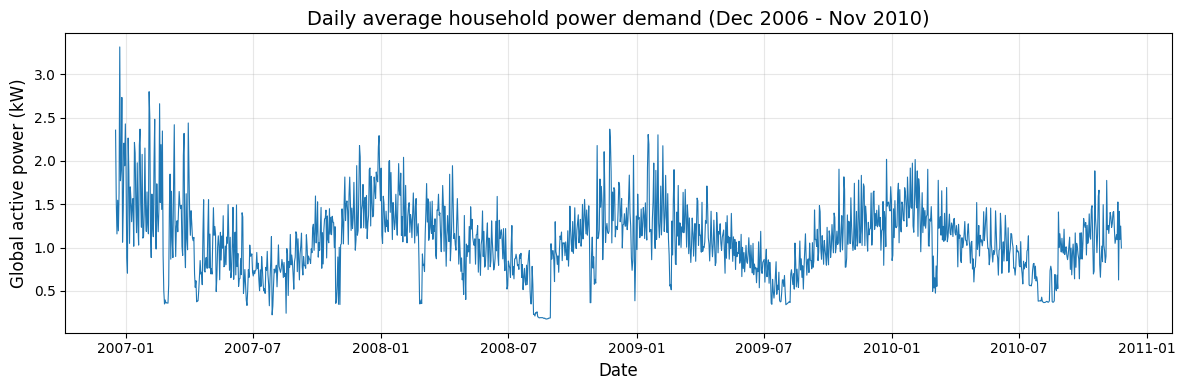

full series plotted


In [45]:
# Hourly data over 4 years is too dense to read, so plot the daily average
daily = target.resample("D").mean()

fig, ax = plt.subplots()
ax.plot(daily.index, daily, linewidth=0.8)
ax.set_title("Daily average household power demand (Dec 2006 - Nov 2010)")
ax.set_xlabel("Date")
ax.set_ylabel("Global active power (kW)")
plt.tight_layout()
plt.show()

print("full series plotted")

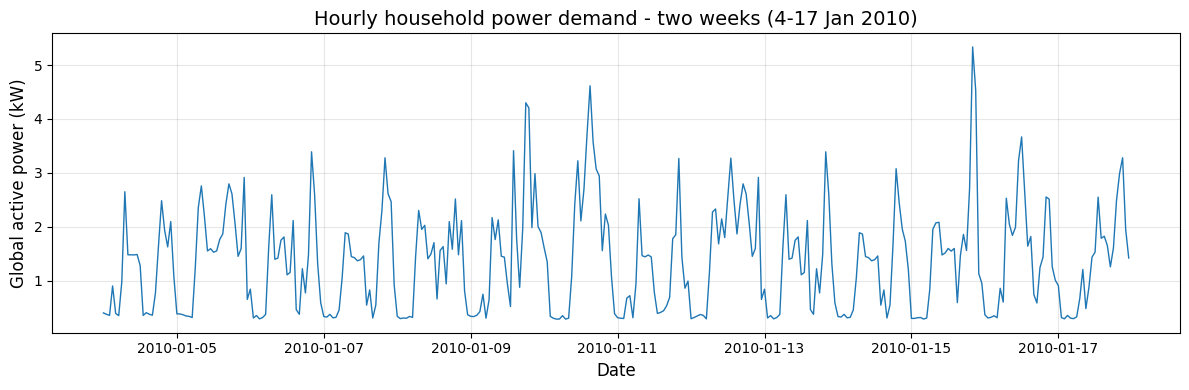

Two-week window: 336 hours, min 0.28 kW, max 5.34 kW


In [46]:
# Zoom into two weeks to see the daily cycle at hourly resolution
two_weeks = target.loc["2010-01-04":"2010-01-17"]

fig, ax = plt.subplots()
ax.plot(two_weeks.index, two_weeks, linewidth=1)
ax.set_title("Hourly household power demand - two weeks (4-17 Jan 2010)")
ax.set_xlabel("Date")
ax.set_ylabel("Global active power (kW)")
plt.tight_layout()
plt.show()

print(f"Two-week window: {len(two_weeks)} hours, "
      f"min {two_weeks.min():.2f} kW, max {two_weeks.max():.2f} kW")

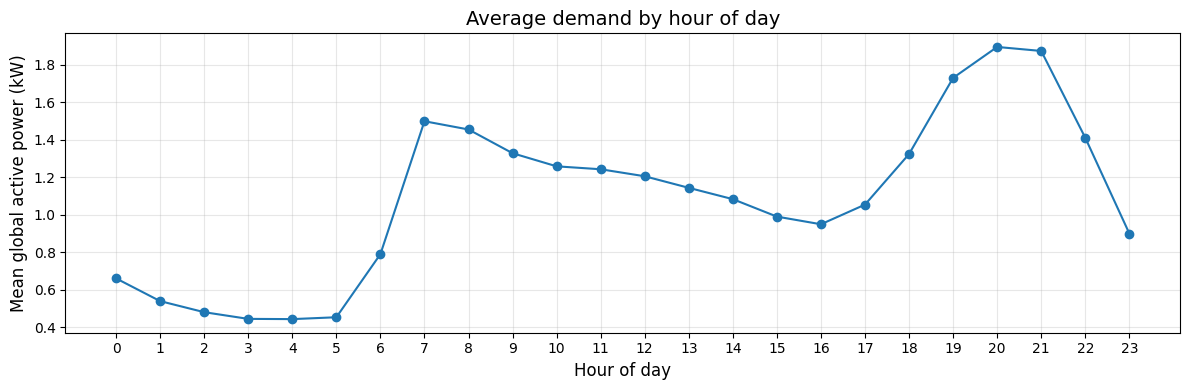

Peak hour: 20:00 (1.89 kW) | Lowest hour: 4:00 (0.44 kW)


In [47]:
# Average demand for each hour of the day, across the whole dataset
hourly_profile = target.groupby(target.index.hour).mean()

fig, ax = plt.subplots()
ax.plot(hourly_profile.index, hourly_profile.values, marker="o")
ax.set_title("Average demand by hour of day")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean global active power (kW)")
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

print(f"Peak hour: {hourly_profile.idxmax()}:00 ({hourly_profile.max():.2f} kW) | "
      f"Lowest hour: {hourly_profile.idxmin()}:00 ({hourly_profile.min():.2f} kW)")

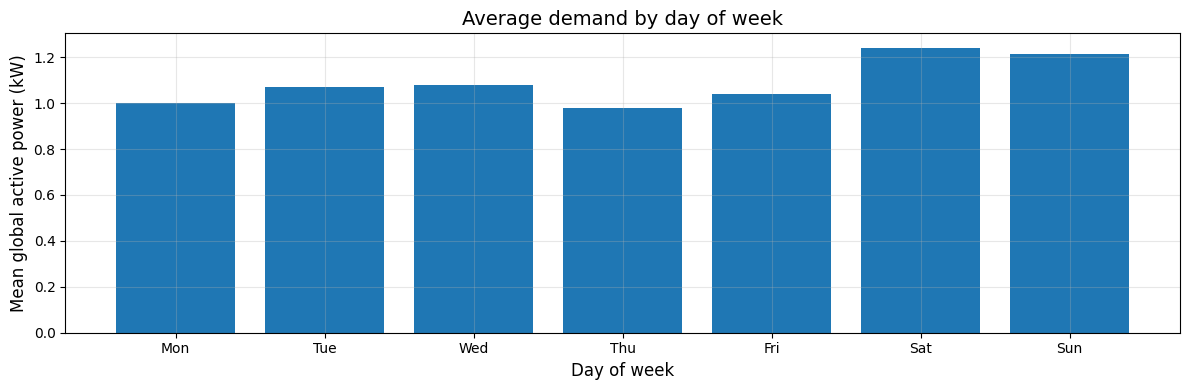

Highest day: Sat (1.24 kW) | Lowest day: Thu (0.98 kW)


In [48]:
# Average demand for each day of the week (0 = Monday, 6 = Sunday)
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekly_profile = target.groupby(target.index.dayofweek).mean()

fig, ax = plt.subplots()
ax.bar(day_names, weekly_profile.values)
ax.set_title("Average demand by day of week")
ax.set_xlabel("Day of week")
ax.set_ylabel("Mean global active power (kW)")
plt.tight_layout()
plt.show()

print(f"Highest day: {day_names[weekly_profile.idxmax()]} ({weekly_profile.max():.2f} kW) | "
      f"Lowest day: {day_names[weekly_profile.idxmin()]} ({weekly_profile.min():.2f} kW)")

## Step 6: Seasonal decomposition
The series is split into trend, seasonal and residual components to
identify what structure it contains. A 24-hour period is used for the
daily cycle. A 4-week window is decomposed so the daily pattern is visible.

In [49]:
# Split four weeks of hourly data into trend + daily seasonal + residual
from statsmodels.tsa.seasonal import seasonal_decompose

window = target.loc["2010-01-04":"2010-01-31"]
decomp_daily = seasonal_decompose(window, model="additive", period=24)

print(f"Decomposition window: {window.index.min().date()} to {window.index.max().date()} "
      f"({len(window)} hours, period = 24)")

Decomposition window: 2010-01-04 to 2010-01-31 (672 hours, period = 24)


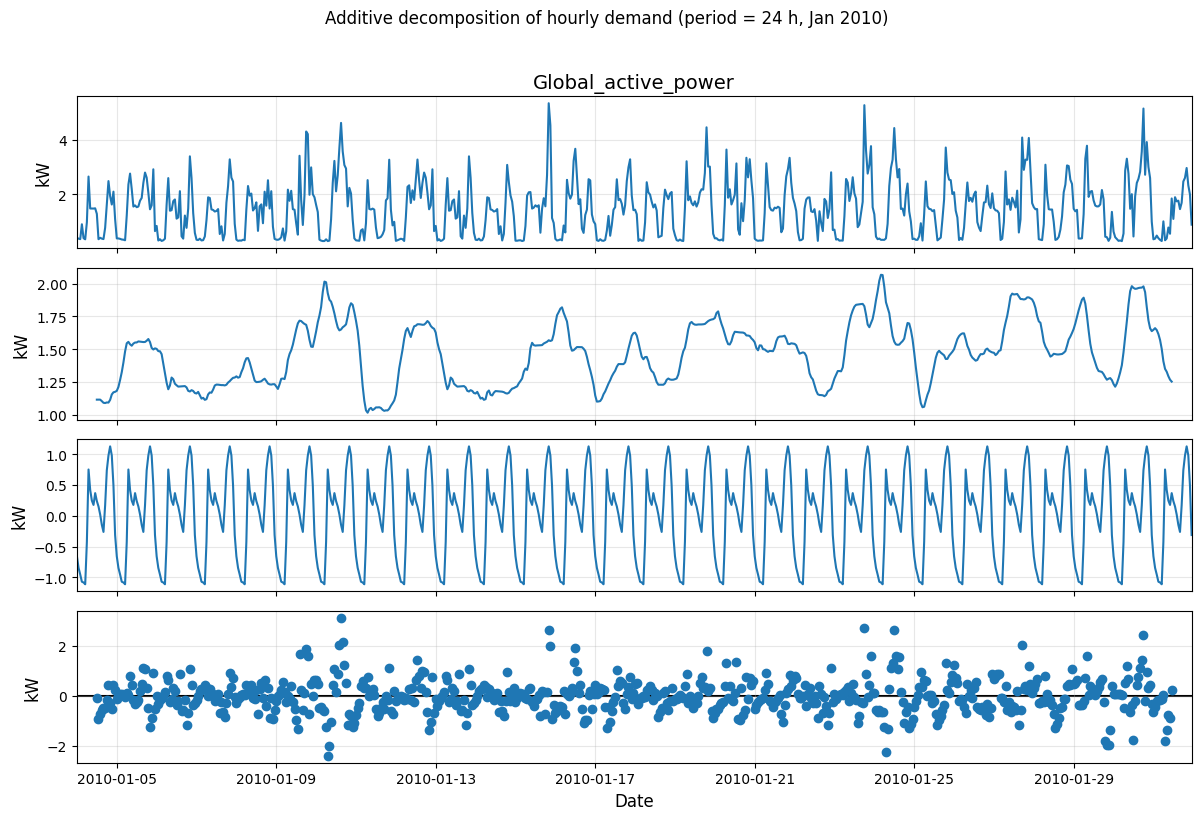

Components: observed, trend, seasonal (24 h), residual


In [50]:
# Plot observed, trend, seasonal and residual components
fig = decomp_daily.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Additive decomposition of hourly demand (period = 24 h, Jan 2010)", y=1.02)
for ax in fig.axes:
    ax.set_ylabel("kW")
fig.axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

print("Components: observed, trend, seasonal (24 h), residual")


In [51]:
# Strength of seasonality (Hyndman & Athanasopoulos): 1 - Var(resid) / Var(seasonal + resid)
# Close to 1 = strong seasonal pattern, close to 0 = weak
resid = decomp_daily.resid.dropna()
seasonal = decomp_daily.seasonal.loc[resid.index]
strength = max(0, 1 - resid.var() / (seasonal + resid).var())

print(f"Daily seasonal strength: {strength:.2f} (0 = none, 1 = very strong)")

Daily seasonal strength: 0.50 (0 = none, 1 = very strong)


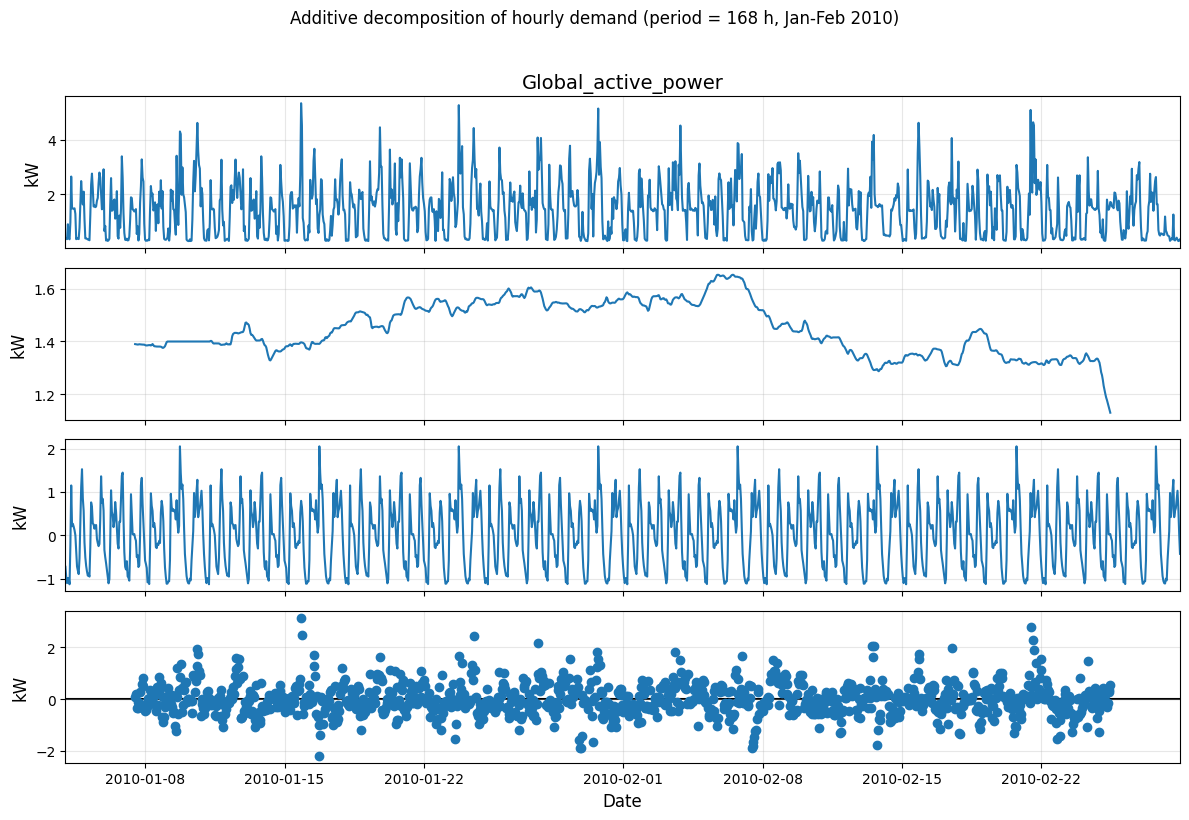

Decomposition window: 2010-01-04 to 2010-02-28 (1344 hours, period = 168)


In [52]:
# Decompose 8 weeks with a 168-hour (weekly) period to isolate the weekly cycle
window_weekly = target.loc["2010-01-04":"2010-02-28"]
decomp_weekly = seasonal_decompose(window_weekly, model="additive", period=168)

fig = decomp_weekly.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Additive decomposition of hourly demand (period = 168 h, Jan-Feb 2010)", y=1.02)
for ax in fig.axes:
    ax.set_ylabel("kW")
fig.axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

print(f"Decomposition window: {window_weekly.index.min().date()} to "
      f"{window_weekly.index.max().date()} ({len(window_weekly)} hours, period = 168)")

## Step 7: Stationarity tests
SARIMA models need a stationary series (constant mean and variance over time).
Two complementary tests are used:
- **ADF**: null hypothesis = series has a unit root (non-stationary).
  p < 0.05 means stationary.
- **KPSS**: null hypothesis = series is stationary.
  p < 0.05 means non-stationary.
Using both together gives a more reliable conclusion than either alone.
ACF and PACF plots are then used to check for autocorrelation and seasonality.

In [57]:
# Reusable function: run ADF and KPSS tests and return a summary table
from statsmodels.tsa.stattools import adfuller, kpss
import warnings

def stationarity_tests(series, name="series"):
    """Run ADF and KPSS tests on a time series.

    Parameters
    ----------
    series : pd.Series
        The time series to test (NaN values are dropped).
    name : str
        Label used in the output table.

    Returns
    -------
    pd.DataFrame
        Test statistic, p-value and conclusion for each test.
    """
    series = series.dropna()

    with warnings.catch_warnings():   # hide version and p-value-table warnings
        warnings.simplefilter("ignore")
        adf_stat, adf_p = adfuller(series, autolag="AIC")[:2]
        kpss_stat, kpss_p = kpss(series, regression="c", nlags="auto")[:2]

    return pd.DataFrame({
        "series": [name, name],
        "test": ["ADF", "KPSS"],
        "statistic": [round(adf_stat, 3), round(kpss_stat, 3)],
        "p_value": [round(adf_p, 4), round(kpss_p, 4)],
        "conclusion": [
            "stationary" if adf_p < 0.05 else "non-stationary",
            "non-stationary" if kpss_p < 0.05 else "stationary",
        ],
    })

print("Function stationarity_tests() defined")

Function stationarity_tests() defined


In [58]:
# Run both tests on the full hourly demand series (may take about a minute)
results_original = stationarity_tests(target, name="original hourly")
print(results_original.to_string(index=False))

         series test  statistic  p_value     conclusion
original hourly  ADF    -14.235     0.00     stationary
original hourly KPSS      1.231     0.01 non-stationary


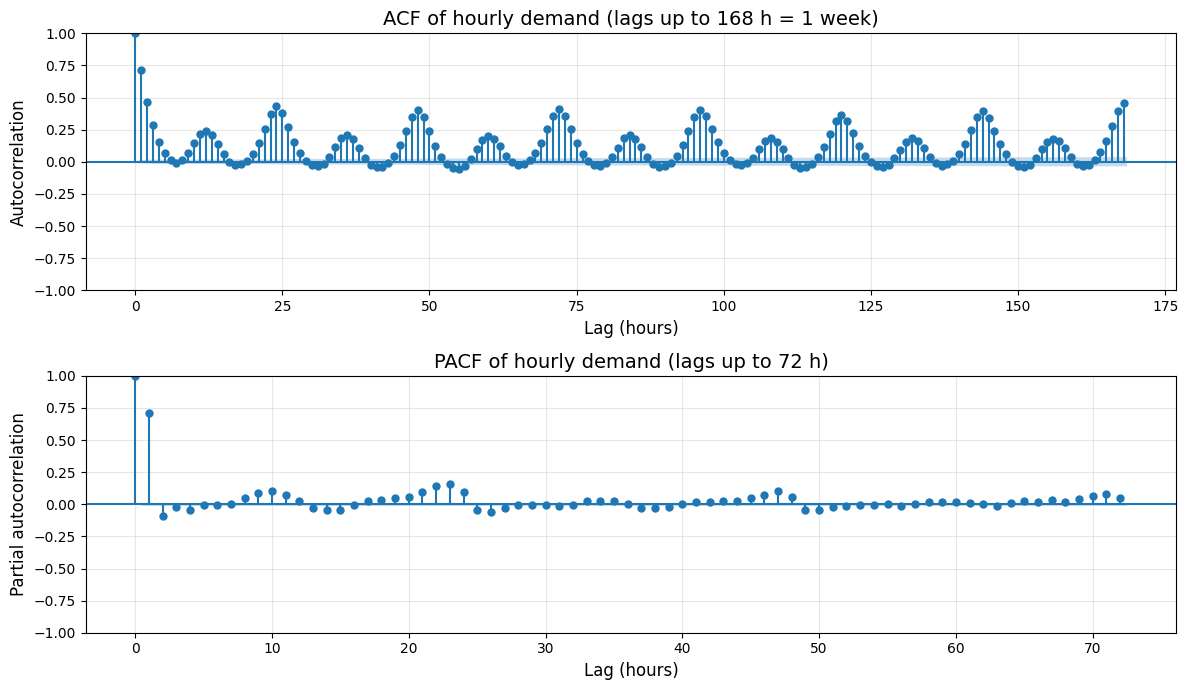

ACF/PACF plotted (lags 0-168 h and 0-72 h)


In [59]:
# Autocorrelation up to 1 week (168 hours) to reveal daily and weekly cycles
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
plot_acf(target, lags=168, ax=axes[0])
axes[0].set_title("ACF of hourly demand (lags up to 168 h = 1 week)")
axes[0].set_xlabel("Lag (hours)")
axes[0].set_ylabel("Autocorrelation")

plot_pacf(target, lags=72, ax=axes[1], method="ywm")
axes[1].set_title("PACF of hourly demand (lags up to 72 h)")
axes[1].set_xlabel("Lag (hours)")
axes[1].set_ylabel("Partial autocorrelation")

plt.tight_layout()
plt.show()

print("ACF/PACF plotted (lags 0-168 h and 0-72 h)")

### Differencing
The ACF shows strong peaks every 24 hours that do not decay, indicating
seasonal non-stationarity. Seasonal differencing (lag 24) removes the
daily cycle; first differencing (lag 1) removes short-term level changes.
Each version is re-tested to find the minimum differencing needed.

In [60]:
# Three candidate transformations of the target
diff_seasonal = target.diff(24)            # seasonal difference: y(t) - y(t-24)
diff_first = target.diff(1)                # first difference:    y(t) - y(t-1)
diff_both = target.diff(24).diff(1)        # seasonal + first difference

# Re-test each one with the same function (may take 2-3 minutes)
results_diff = pd.concat([
    results_original,
    stationarity_tests(diff_seasonal, "seasonal diff (24)"),
    stationarity_tests(diff_first, "first diff (1)"),
    stationarity_tests(diff_both, "seasonal + first diff"),
], ignore_index=True)

print(results_diff.to_string(index=False))

               series test  statistic  p_value     conclusion
      original hourly  ADF    -14.235     0.00     stationary
      original hourly KPSS      1.231     0.01 non-stationary
   seasonal diff (24)  ADF    -41.464     0.00     stationary
   seasonal diff (24) KPSS      0.007     0.10     stationary
       first diff (1)  ADF    -43.032     0.00     stationary
       first diff (1) KPSS      0.006     0.10     stationary
seasonal + first diff  ADF    -44.832     0.00     stationary
seasonal + first diff KPSS      0.072     0.10     stationary


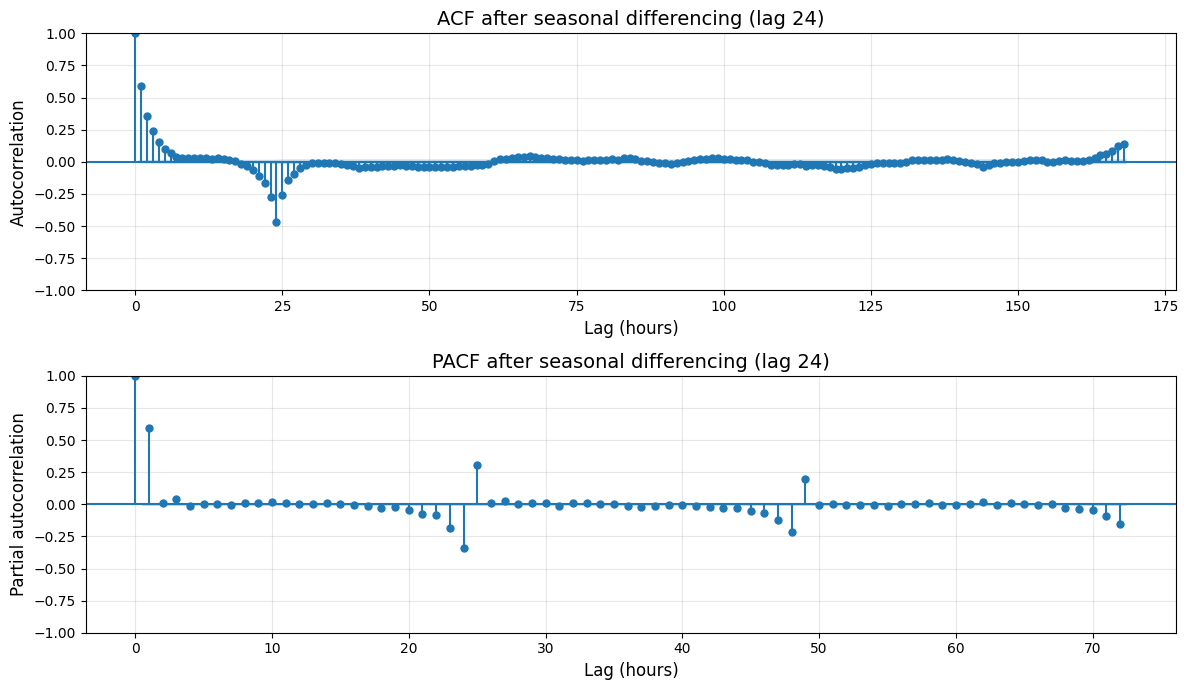

ACF/PACF of seasonally differenced series plotted


In [61]:
# Check whether the 24-hour peaks are gone after seasonal differencing
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
plot_acf(diff_seasonal.dropna(), lags=168, ax=axes[0])
axes[0].set_title("ACF after seasonal differencing (lag 24)")
axes[0].set_xlabel("Lag (hours)")
axes[0].set_ylabel("Autocorrelation")

plot_pacf(diff_seasonal.dropna(), lags=72, ax=axes[1], method="ywm")
axes[1].set_title("PACF after seasonal differencing (lag 24)")
axes[1].set_xlabel("Lag (hours)")
axes[1].set_ylabel("Partial autocorrelation")

plt.tight_layout()
plt.show()

print("ACF/PACF of seasonally differenced series plotted")

## Step 8: Forecasting problem definition (Part 2)
- **Target:** `Global_active_power` (hourly mean, kW)
- **Horizon:** 24 hours ahead
- **Split:** last 14 days = test, everything before = train
- **Metrics:** RMSE, MAE, MAPE, MASE (MASE < 1 = better than daily seasonal naive)

In [62]:
# Forecasting settings used in every later step
TARGET = "Global_active_power"
HORIZON = 24      # forecast 24 hours ahead
TEST_DAYS = 14    # last 14 days held out for testing
SEASON = 24       # daily seasonal period (hours)

print(f"Target: {TARGET} | Horizon: {HORIZON} h | Test: {TEST_DAYS} days | Season: {SEASON} h")

Target: Global_active_power | Horizon: 24 h | Test: 14 days | Season: 24 h


In [63]:
# Split: everything before the last 14 days = train, last 14 days = test
split_point = df_hourly_clean.index.max() - pd.Timedelta(days=TEST_DAYS) + pd.Timedelta(hours=1)
train = df_hourly_clean.loc[:split_point - pd.Timedelta(hours=1)]
test = df_hourly_clean.loc[split_point:]

print(f"Train: {train.index.min()} to {train.index.max()} ({len(train):,} hours)")
print(f"Test:  {test.index.min()} to {test.index.max()} ({len(test)} hours)")

Train: 2006-12-17 00:00:00 to 2010-11-11 23:00:00 (34,224 hours)
Test:  2010-11-12 00:00:00 to 2010-11-25 23:00:00 (336 hours)


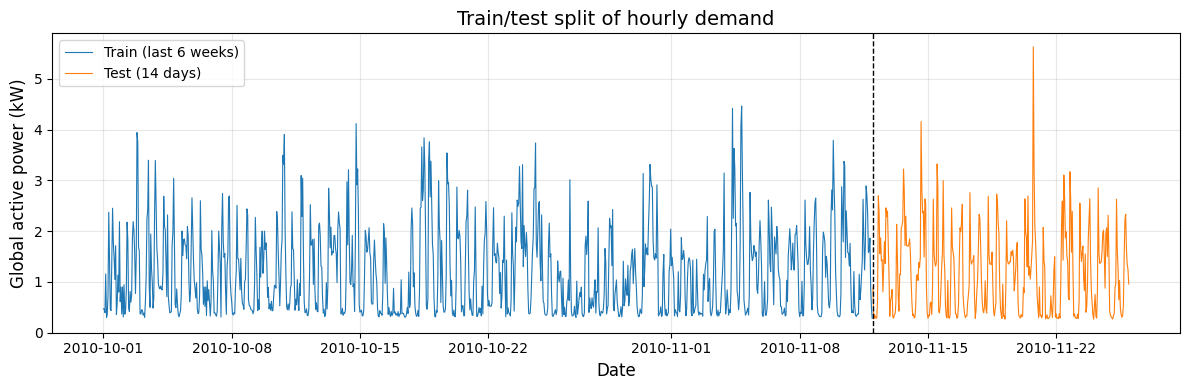

Split point: 2010-11-12 00:00:00


In [64]:
# Show the last 6 weeks of training data and the 14-day test period
fig, ax = plt.subplots()
ax.plot(train[TARGET].iloc[-24*42:], label="Train (last 6 weeks)", linewidth=0.8)
ax.plot(test[TARGET], label="Test (14 days)", linewidth=0.8, color="tab:orange")
ax.axvline(split_point, color="black", linestyle="--", linewidth=1)
ax.set_title("Train/test split of hourly demand")
ax.set_xlabel("Date")
ax.set_ylabel("Global active power (kW)")
ax.legend()
plt.tight_layout()
plt.show()

print("Split point:", split_point)

In [65]:
# Root mean squared error - penalises large errors more
def rmse(actual, forecast):
    return np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2))

# Mean absolute error - average size of the error in kW
def mae(actual, forecast):
    return np.mean(np.abs(np.asarray(actual) - np.asarray(forecast)))

print("rmse() and mae() defined")

rmse() and mae() defined


In [66]:
# Mean absolute percentage error (%)
def mape(actual, forecast):
    actual, forecast = np.asarray(actual), np.asarray(forecast)
    return np.mean(np.abs((actual - forecast) / actual)) * 100

# Mean absolute scaled error: MAE divided by the in-sample daily seasonal naive MAE
# MASE < 1 means the model beats the daily seasonal naive forecast
def mase(actual, forecast, train_series, season=SEASON):
    y = np.asarray(train_series)
    scale = np.mean(np.abs(y[season:] - y[:-season]))
    return mae(actual, forecast) / scale

print("mape() and mase() defined")

mape() and mase() defined


In [67]:
# A perfect forecast should give zero error for every metric
check = test[TARGET].iloc[:24]
print(f"Perfect forecast -> RMSE={rmse(check, check):.2f}, MAE={mae(check, check):.2f}, "
      f"MAPE={mape(check, check):.2f}, MASE={mase(check, check, train[TARGET]):.2f}")

Perfect forecast -> RMSE=0.00, MAE=0.00, MAPE=0.00, MASE=0.00


## Step 9: Benchmark models (Part 3)
Five simple benchmarks set the baseline that more complex models must beat:
- **Mean:** average of all past values
- **Naive:** last observed value repeated
- **Seasonal naive (daily):** same hour on the previous day
- **Seasonal naive (weekly):** same hour one week earlier
- **Drift:** last value plus the average change over the history

Each model makes 14 separate 24-hour forecasts, one from midnight of each
test day, using only data available before that day (rolling origin).

In [68]:
def benchmark_forecasts(history, horizon=HORIZON):
    """Return 24-hour forecasts from five benchmark models.

    history : pd.Series of past hourly values (ends just before the forecast starts)
    horizon : number of hours to forecast (must be <= 24 for the daily seasonal naive)
    """
    y = history.values
    future_index = pd.date_range(history.index[-1] + pd.Timedelta(hours=1),
                                 periods=horizon, freq="h")
    slope = (y[-1] - y[0]) / (len(y) - 1)     # average change per hour (drift)

    return pd.DataFrame({
        "Mean": np.full(horizon, y.mean()),
        "Naive": np.full(horizon, y[-1]),
        "Seasonal naive (daily)": y[-24:][:horizon],
        "Seasonal naive (weekly)": y[-168:-168 + horizon],
        "Drift": y[-1] + slope * np.arange(1, horizon + 1),
    }, index=future_index)

print("benchmark_forecasts() defined")

benchmark_forecasts() defined


In [69]:
# One 24-hour forecast from midnight of each of the 14 test days
series = df_hourly_clean[TARGET]
test_days = pd.date_range(split_point, periods=TEST_DAYS, freq="D")

daily_forecasts = []
for day in test_days:
    history = series.loc[:day - pd.Timedelta(hours=1)]   # only data before this day
    daily_forecasts.append(benchmark_forecasts(history))

bench_fc = pd.concat(daily_forecasts)
bench_fc.insert(0, "Actual", test[TARGET])

print(f"Forecasts made: {len(test_days)} days x {HORIZON} h = {len(bench_fc)} hours")

Forecasts made: 14 days x 24 h = 336 hours


In [70]:
def evaluate_models(forecast_df, actual_col="Actual", train_series=None):
    """Compute RMSE, MAE, MAPE and MASE for every forecast column, sorted by RMSE."""
    actual = forecast_df[actual_col]
    rows = []
    for model in forecast_df.columns.drop(actual_col):
        fc = forecast_df[model]
        rows.append({
            "Model": model,
            "RMSE": rmse(actual, fc),
            "MAE": mae(actual, fc),
            "MAPE (%)": mape(actual, fc),
            "MASE": mase(actual, fc, train_series),
        })
    return pd.DataFrame(rows).sort_values("RMSE").round(3).reset_index(drop=True)

bench_metrics = evaluate_models(bench_fc, train_series=train[TARGET])
print(bench_metrics.to_string(index=False))

                  Model  RMSE   MAE  MAPE (%)  MASE
Seasonal naive (weekly) 0.832 0.573    70.079 0.897
                   Mean 0.838 0.678    97.666 1.061
 Seasonal naive (daily) 0.906 0.585    74.554 0.914
                  Naive 1.094 0.809    65.399 1.266
                  Drift 1.095 0.810    65.411 1.266


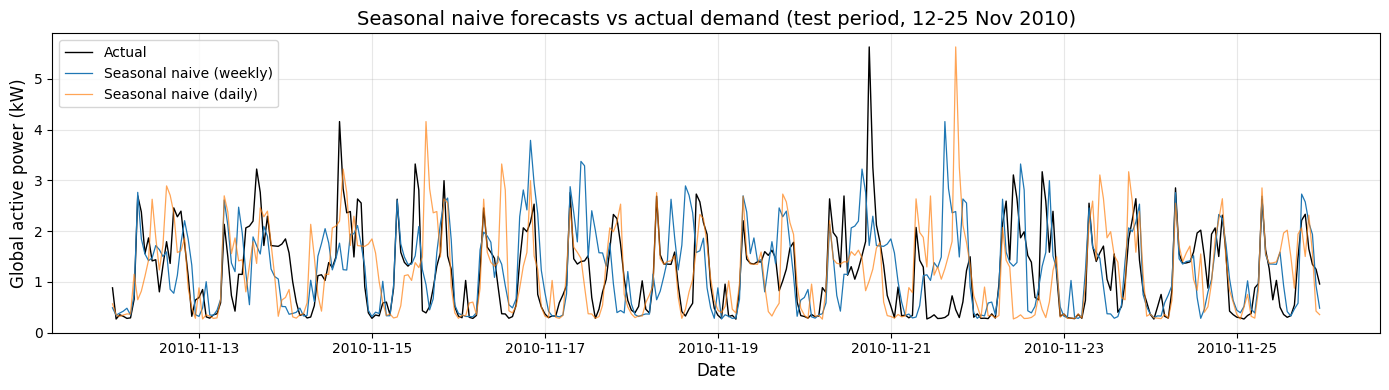

Plotted: actual vs daily and weekly seasonal naive (336 hours)


In [71]:
# Actual demand vs the two seasonal naive forecasts across all 14 test days
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(bench_fc.index, bench_fc["Actual"], label="Actual", color="black", linewidth=1)
ax.plot(bench_fc.index, bench_fc["Seasonal naive (weekly)"], label="Seasonal naive (weekly)", linewidth=0.9)
ax.plot(bench_fc.index, bench_fc["Seasonal naive (daily)"], label="Seasonal naive (daily)", linewidth=0.9, alpha=0.7)
ax.set_title("Seasonal naive forecasts vs actual demand (test period, 12-25 Nov 2010)")
ax.set_xlabel("Date")
ax.set_ylabel("Global active power (kW)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print("Plotted: actual vs daily and weekly seasonal naive (336 hours)")

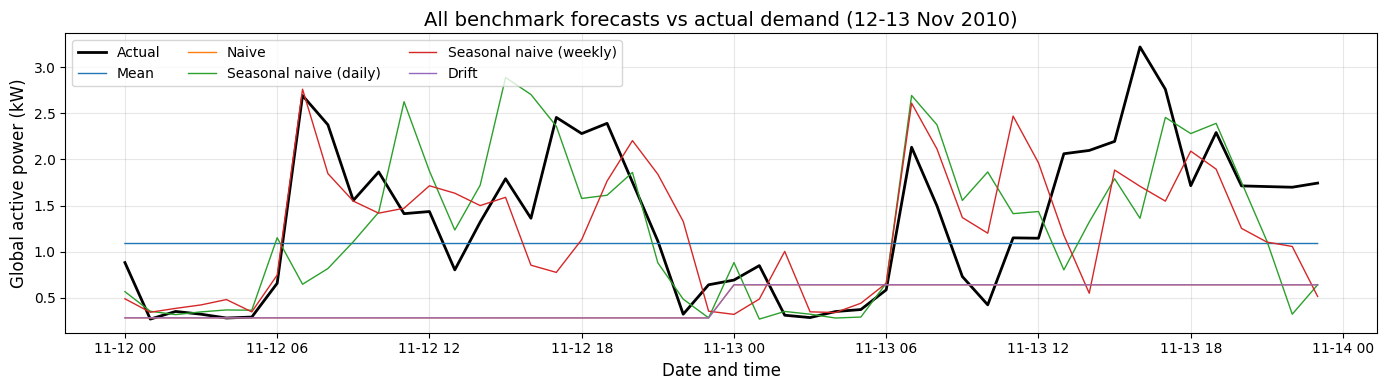

Plotted: all five benchmarks over 48 hours


In [72]:
# Zoom into the first two test days so all five forecasts are readable
zoom = bench_fc.loc["2010-11-12":"2010-11-13"]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(zoom.index, zoom["Actual"], label="Actual", color="black", linewidth=2)
for model in ["Mean", "Naive", "Seasonal naive (daily)", "Seasonal naive (weekly)", "Drift"]:
    ax.plot(zoom.index, zoom[model], label=model, linewidth=1)
ax.set_title("All benchmark forecasts vs actual demand (12-13 Nov 2010)")
ax.set_xlabel("Date and time")
ax.set_ylabel("Global active power (kW)")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout()
plt.show()

print("Plotted: all five benchmarks over 48 hours")

In [73]:
# Save forecasts and metrics so they can be combined with other models in the final comparison
os.makedirs("results", exist_ok=True)
bench_fc.to_csv("results/benchmark_forecasts.csv")
bench_metrics.to_csv("results/benchmark_metrics.csv", index=False)

best_benchmark = bench_metrics.iloc[0]
print(f"Saved results/benchmark_forecasts.csv and results/benchmark_metrics.csv")
print(f"Strongest benchmark: {best_benchmark['Model']} (RMSE {best_benchmark['RMSE']:.3f})")

Saved results/benchmark_forecasts.csv and results/benchmark_metrics.csv
Strongest benchmark: Seasonal naive (weekly) (RMSE 0.832)


## Step 10: SARIMA model (Part 4)
The seasonally differenced series (Step 7) showed an AR(1)-like decay in the ACF
and a single negative spike at lag 24, suggesting a seasonal MA term.
The seasonal part is therefore set to (P, D, Q, s) = (0, 1, 1, 24).
The non-seasonal orders are chosen by AIC over p = 0-6, d = 0-2, q = 0-6 (147 models).
To keep the grid search computationally feasible, models are fitted on the
most recent 4 weeks of training data (672 hours).

In [74]:
# Use the last 4 weeks of training data, with an explicit hourly frequency
SARIMA_WEEKS = 4
y_window = train[TARGET].iloc[-24 * 7 * SARIMA_WEEKS:].asfreq("h")

print(f"SARIMA training window: {y_window.index.min()} to {y_window.index.max()} "
      f"({len(y_window)} hours)")

SARIMA training window: 2010-10-15 00:00:00 to 2010-11-11 23:00:00 (672 hours)


In [75]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import time

def fit_sarima(y, order, seasonal_order=(0, 1, 1, 24), exog=None):
    """Fit a SARIMA/SARIMAX model and return the fitted result (warnings hidden)."""
    model = SARIMAX(y, exog=exog, order=order, seasonal_order=seasonal_order,
                    enforce_stationarity=False, enforce_invertibility=False)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return model.fit(disp=False, maxiter=50)

print("fit_sarima() defined")

fit_sarima() defined


In [76]:
# Fit the model suggested by the ACF/PACF and measure how long it takes
start = time.time()
test_fit = fit_sarima(y_window, order=(1, 0, 0))
seconds = time.time() - start

print(f"SARIMA(1,0,0)(0,1,1,24): AIC = {test_fit.aic:.1f}, fitted in {seconds:.1f} s")
print(f"Rough estimate for 147 models: {seconds * 147 * 3 / 60:.0f} minutes "
      f"(larger models are slower)")

SARIMA(1,0,0)(0,1,1,24): AIC = 1154.7, fitted in 3.5 s
Rough estimate for 147 models: 26 minutes (larger models are slower)


In [77]:
import itertools

def sarima_grid_search(y, p_values, d_values, q_values, seasonal_order, save_path):
    """Fit every (p, d, q) combination, record AIC, and save progress after each model.
    If save_path already has results, finished combinations are skipped (resume)."""
    rows = pd.read_csv(save_path).to_dict("records") if os.path.exists(save_path) else []
    done = {(r["p"], r["d"], r["q"]) for r in rows}
    combos = list(itertools.product(p_values, d_values, q_values))

    for p, d, q in combos:
        if (p, d, q) in done:
            continue
        start = time.time()
        try:
            aic = fit_sarima(y, (p, d, q), seasonal_order).aic
        except Exception:
            aic = np.nan                      # model failed to fit
        rows.append({"p": p, "d": d, "q": q, "aic": aic,
                     "seconds": round(time.time() - start, 1)})
        pd.DataFrame(rows).to_csv(save_path, index=False)
        if len(rows) % 10 == 0:
            print(f"Progress: {len(rows)}/{len(combos)} models fitted")

    return pd.DataFrame(rows).sort_values("aic").reset_index(drop=True)

print("sarima_grid_search() defined")

sarima_grid_search() defined


In [80]:
# Set to False after the first full run to load saved results instead of refitting
RUN_GRID_SEARCH = False
GRID_PATH = "results/sarima_grid_search.csv"

if RUN_GRID_SEARCH or not os.path.exists(GRID_PATH):
    grid = sarima_grid_search(y_window, range(0, 7), range(0, 3), range(0, 7),
                              seasonal_order=(0, 1, 1, 24), save_path=GRID_PATH)
else:
    grid = pd.read_csv(GRID_PATH).sort_values("aic").reset_index(drop=True)

print(f"Models fitted: {len(grid)} | failed: {grid['aic'].isna().sum()}")
print("Top 10 models by AIC:")
print(grid.head(10).to_string(index=False))

Models fitted: 147 | failed: 0
Top 10 models by AIC:
 p  d  q         aic  seconds
 6  0  6 1142.715721     47.3
 6  1  6 1143.768925     49.6
 4  0  3 1144.049558     35.7
 3  0  6 1144.845664     41.0
 4  0  6 1145.268960     47.5
 4  0  5 1145.556036     43.4
 5  0  5 1146.677901     46.4
 2  0  6 1148.237506     35.2
 2  0  5 1148.243774     27.3
 3  0  5 1150.119375     24.2


In [81]:
# With the best (p, d, q) fixed, compare seasonal orders P, Q in {0, 1} (D = 1, s = 24)
best_order = tuple(int(v) for v in grid.loc[0, ["p", "d", "q"]])

seasonal_rows = []
for P, Q in itertools.product([0, 1], [0, 1]):
    start = time.time()
    aic = fit_sarima(y_window, best_order, seasonal_order=(P, 1, Q, 24)).aic
    seasonal_rows.append({"P": P, "D": 1, "Q": Q, "aic": round(aic, 1),
                          "seconds": round(time.time() - start, 1)})

seasonal_grid = pd.DataFrame(seasonal_rows).sort_values("aic").reset_index(drop=True)
print(f"Seasonal order comparison for SARIMA{best_order}:")
print(seasonal_grid.to_string(index=False))

Seasonal order comparison for SARIMA(6, 0, 6):
 P  D  Q    aic  seconds
 0  1  1 1142.7     48.4
 1  1  1 1153.4     51.5
 1  1  0 1298.1     42.3
 0  1  0 1426.2     15.9


In [82]:
# Fit the selected model on the 4-week training window
SARIMA_ORDER = best_order                  # (6, 0, 6) from the AIC grid search
SARIMA_SEASONAL = (0, 1, 1, 24)            # from the seasonal comparison
sarima_fit = fit_sarima(y_window, SARIMA_ORDER, SARIMA_SEASONAL)

print(f"Final model: SARIMA{SARIMA_ORDER}{SARIMA_SEASONAL}")
print(f"AIC = {sarima_fit.aic:.1f} | parameters = {len(sarima_fit.params)}")

Final model: SARIMA(6, 0, 6)(0, 1, 1, 24)
AIC = 1142.7 | parameters = 14


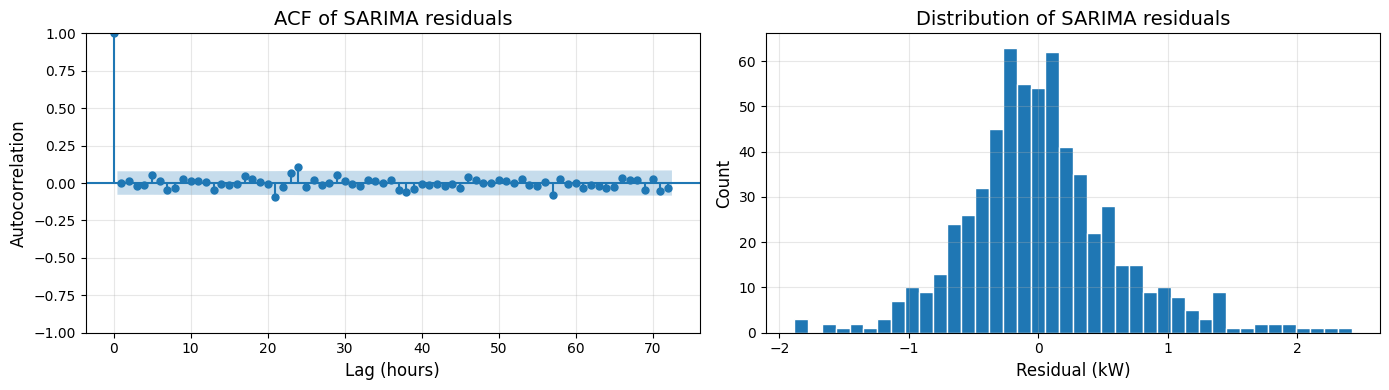

Residual mean: 0.018 kW | std: 0.596 kW


In [83]:
# Residuals should look like white noise: no autocorrelation, centred on zero.
# The first 48 hours are skipped because differencing needs a start-up period.
resid = sarima_fit.resid.iloc[48:]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(resid, lags=72, ax=axes[0])
axes[0].set_title("ACF of SARIMA residuals")
axes[0].set_xlabel("Lag (hours)")
axes[0].set_ylabel("Autocorrelation")

axes[1].hist(resid, bins=40, edgecolor="white")
axes[1].set_title("Distribution of SARIMA residuals")
axes[1].set_xlabel("Residual (kW)")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

print(f"Residual mean: {resid.mean():.3f} kW | std: {resid.std():.3f} kW")

In [84]:
# Ljung-Box: p > 0.05 means no significant autocorrelation left (good)
# Skewness/kurtosis: normal residuals have skew ~0 and excess kurtosis ~0
from statsmodels.stats.diagnostic import acorr_ljungbox

lb = acorr_ljungbox(resid, lags=[24, 48], return_df=True)
print("Ljung-Box test on residuals:")
print(lb.round(4))
print(f"\nSkewness: {resid.skew():.2f} | Excess kurtosis: {resid.kurt():.2f}")

Ljung-Box test on residuals:
    lb_stat  lb_pvalue
24  24.4349     0.4370
48  35.9188     0.9007

Skewness: 0.53 | Excess kurtosis: 1.67


In [85]:
# Forecast each test day from midnight, then add that day's actual data to the
# model (without refitting the parameters) before forecasting the next day
sarima_days = []
current = sarima_fit

for day in test_days:
    fc = current.get_forecast(steps=HORIZON)
    ci = fc.conf_int(alpha=0.05)
    sarima_days.append(pd.DataFrame({
        "SARIMA": fc.predicted_mean,
        "lower_95": ci.iloc[:, 0],
        "upper_95": ci.iloc[:, 1],
    }))
    actual_day = series.loc[day:day + pd.Timedelta(hours=23)].asfreq("h")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        current = current.append(actual_day, refit=False)

sarima_fc = pd.concat(sarima_days)
sarima_fc.insert(0, "Actual", test[TARGET])
print(f"SARIMA forecasts made: {len(sarima_fc)} hours ({len(test_days)} days)")

SARIMA forecasts made: 336 hours (14 days)


In [86]:
# Compare SARIMA with the weekly seasonal naive benchmark
compare_df = pd.DataFrame({
    "Actual": sarima_fc["Actual"],
    "SARIMA": sarima_fc["SARIMA"],
    "Seasonal naive (weekly)": bench_fc["Seasonal naive (weekly)"],
})
sarima_metrics = evaluate_models(compare_df, train_series=train[TARGET])
print(sarima_metrics.to_string(index=False))

# Share of actual values that fall inside the 95% interval (ideal: about 95%)
inside = ((sarima_fc["Actual"] >= sarima_fc["lower_95"]) &
          (sarima_fc["Actual"] <= sarima_fc["upper_95"])).mean() * 100
print(f"\n95% interval coverage: {inside:.1f}% of actual values")

                  Model  RMSE   MAE  MAPE (%)  MASE
                 SARIMA 0.632 0.445    60.986 0.697
Seasonal naive (weekly) 0.832 0.573    70.079 0.897

95% interval coverage: 97.9% of actual values


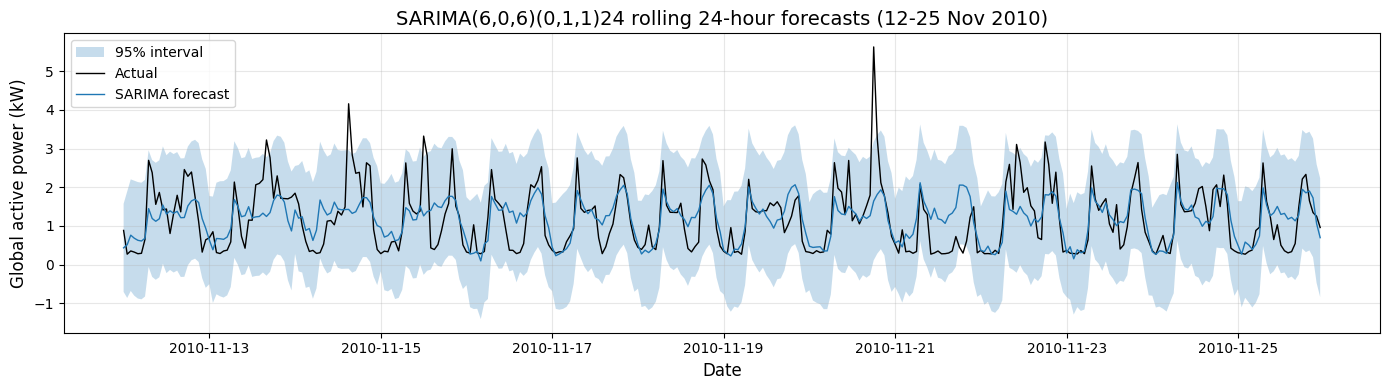

Plotted: SARIMA forecasts with 95% interval (336 hours)


In [87]:
# Actual demand, SARIMA forecast and its 95% confidence interval over all 14 test days
fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(sarima_fc.index, sarima_fc["lower_95"], sarima_fc["upper_95"],
                alpha=0.25, label="95% interval")
ax.plot(sarima_fc.index, sarima_fc["Actual"], color="black", linewidth=1, label="Actual")
ax.plot(sarima_fc.index, sarima_fc["SARIMA"], linewidth=1, label="SARIMA forecast")
ax.set_title("SARIMA(6,0,6)(0,1,1)24 rolling 24-hour forecasts (12-25 Nov 2010)")
ax.set_xlabel("Date")
ax.set_ylabel("Global active power (kW)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print("Plotted: SARIMA forecasts with 95% interval (336 hours)")

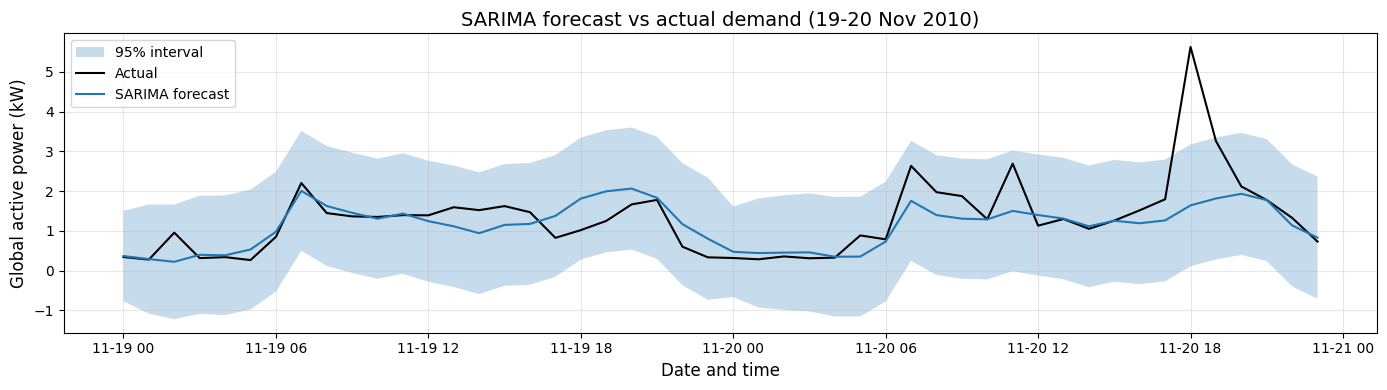

Plotted: SARIMA forecast for 19-20 Nov 2010


In [88]:
# Two test days in detail, including the 20 Nov spike
zoom = sarima_fc.loc["2010-11-19":"2010-11-20"]

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(zoom.index, zoom["lower_95"], zoom["upper_95"], alpha=0.25, label="95% interval")
ax.plot(zoom.index, zoom["Actual"], color="black", linewidth=1.5, label="Actual")
ax.plot(zoom.index, zoom["SARIMA"], linewidth=1.5, label="SARIMA forecast")
ax.set_title("SARIMA forecast vs actual demand (19-20 Nov 2010)")
ax.set_xlabel("Date and time")
ax.set_ylabel("Global active power (kW)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print("Plotted: SARIMA forecast for 19-20 Nov 2010")

In [89]:
# Save SARIMA forecasts and metrics for the final comparison
sarima_fc.to_csv("results/sarima_forecasts.csv")
sarima_metrics.to_csv("results/sarima_metrics.csv", index=False)

print("Saved results/sarima_forecasts.csv and results/sarima_metrics.csv")
print(f"SARIMA RMSE {sarima_metrics.loc[sarima_metrics.Model == 'SARIMA', 'RMSE'].item():.3f} "
      f"vs weekly seasonal naive {best_benchmark['RMSE']:.3f}")

Saved results/sarima_forecasts.csv and results/sarima_metrics.csv
SARIMA RMSE 0.632 vs weekly seasonal naive 0.832


## Step 11: SARIMAX with exogenous variables (Part 5)
Two SARIMAX versions are compared with the plain SARIMA model:
- **A – calendar feature (weekend flag):** known in advance, so this is a true forecast.
- **B – measured variables (Global_reactive_power, Voltage, Global_intensity):**
  their future values are NOT known at the forecast origin. Using the actual
  test-period values makes this a conditional forecast, not a true forecast.
The same (6,0,6)(0,1,1,24) order is used so only the inputs change.
Measured variables are standardised using training-window statistics only.

In [90]:
# Calendar feature: 1 on Saturday/Sunday, 0 on weekdays
exog_all = pd.DataFrame(index=df_hourly_clean.index)
exog_all["is_weekend"] = (exog_all.index.dayofweek >= 5).astype(int)

# Measured variables, standardised with the SARIMA training window's mean/std (no test data used)
MEASURED = ["Global_reactive_power", "Voltage", "Global_intensity"]
for col in MEASURED:
    window_vals = df_hourly_clean.loc[y_window.index, col]
    exog_all[col] = (df_hourly_clean[col] - window_vals.mean()) / window_vals.std()

print("Correlation of each variable with Global_active_power (full data):")
print(df_hourly_clean[[TARGET] + MEASURED].corr()[TARGET].drop(TARGET).round(3))

Correlation of each variable with Global_active_power (full data):
Global_reactive_power    0.314
Voltage                 -0.379
Global_intensity         0.999
Name: Global_active_power, dtype: float64


In [91]:
def rolling_forecast(fit, exog_cols=None):
    """Make one 24-hour forecast per test day from a fitted SARIMA/SARIMAX model.
    After each day, that day's actual data is appended (parameters not refitted).
    Note: exog values for the forecast day come from the data itself, which is only
    a genuine forecast if those variables are known in advance (e.g. calendar)."""
    days, current = [], fit
    for day in test_days:
        day_idx = pd.date_range(day, periods=HORIZON, freq="h")
        x_day = exog_all.loc[day_idx, exog_cols] if exog_cols else None
        fc = current.get_forecast(steps=HORIZON, exog=x_day)
        ci = fc.conf_int(alpha=0.05)
        days.append(pd.DataFrame({"forecast": fc.predicted_mean.values,
                                  "lower_95": ci.iloc[:, 0].values,
                                  "upper_95": ci.iloc[:, 1].values}, index=day_idx))
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            current = current.append(series.loc[day_idx].asfreq("h"), exog=x_day, refit=False)
    out = pd.concat(days)
    out.insert(0, "Actual", test[TARGET])
    return out

print("rolling_forecast() defined")

rolling_forecast() defined


In [92]:
# Fit and forecast with the calendar feature only (about 1 minute)
X_window = exog_all.loc[y_window.index]
fit_cal = fit_sarima(y_window, SARIMA_ORDER, SARIMA_SEASONAL, exog=X_window[["is_weekend"]])
fc_cal = rolling_forecast(fit_cal, ["is_weekend"])

print(f"SARIMAX (weekend flag): AIC = {fit_cal.aic:.1f} (SARIMA was {sarima_fit.aic:.1f})")
print(f"Weekend coefficient: {fit_cal.params['is_weekend']:.3f} kW")

SARIMAX (weekend flag): AIC = 1142.3 (SARIMA was 1142.7)
Weekend coefficient: 0.213 kW


In [93]:
# WARNING: uses the ACTUAL future values of the measured variables during the test days.
# These are not known at the forecast origin -> this is a conditional forecast.
fit_meas = fit_sarima(y_window, SARIMA_ORDER, SARIMA_SEASONAL, exog=X_window[MEASURED])
fc_meas = rolling_forecast(fit_meas, MEASURED)

print(f"SARIMAX (measured variables): AIC = {fit_meas.aic:.1f} (SARIMA was {sarima_fit.aic:.1f})")
print("Coefficients:")
print(fit_meas.params[MEASURED].round(3))

SARIMAX (measured variables): AIC = -2797.1 (SARIMA was 1142.7)
Coefficients:
Global_reactive_power   -0.012
Voltage                  0.017
Global_intensity         0.859
dtype: float64


In [94]:
# Plain SARIMA vs both SARIMAX versions vs the strongest benchmark
sarimax_compare = pd.DataFrame({
    "Actual": sarima_fc["Actual"],
    "SARIMA": sarima_fc["SARIMA"],
    "SARIMAX A (weekend flag)": fc_cal["forecast"],
    "SARIMAX B (measured, conditional)": fc_meas["forecast"],
    "Seasonal naive (weekly)": bench_fc["Seasonal naive (weekly)"],
})
sarimax_metrics = evaluate_models(sarimax_compare, train_series=train[TARGET])
print(sarimax_metrics.to_string(index=False))

                            Model  RMSE   MAE  MAPE (%)  MASE
SARIMAX B (measured, conditional) 0.028 0.017     1.875 0.026
                           SARIMA 0.632 0.445    60.986 0.697
         SARIMAX A (weekend flag) 0.638 0.459    63.740 0.718
          Seasonal naive (weekly) 0.832 0.573    70.079 0.897


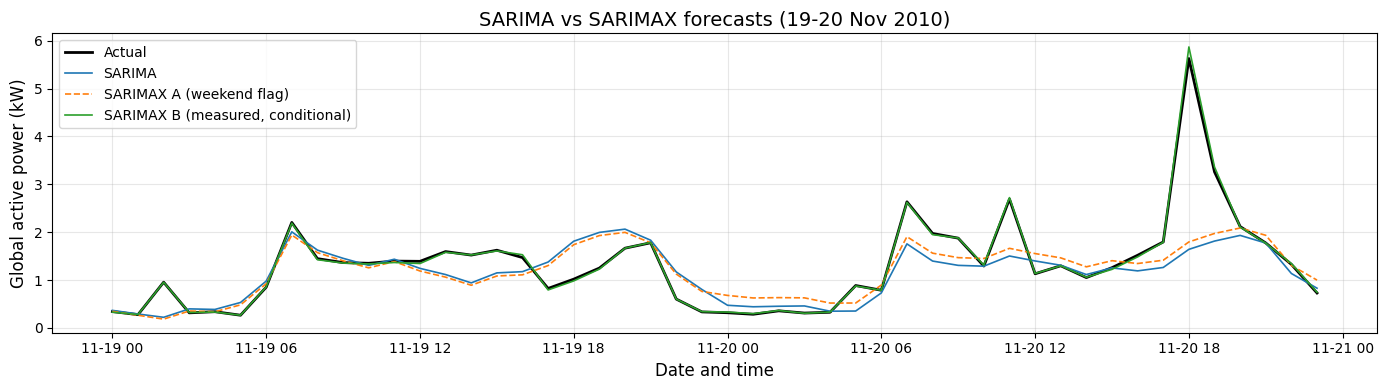

Plotted: SARIMA, SARIMAX A and SARIMAX B for 19-20 Nov 2010


In [95]:
# Show why SARIMAX B looks almost perfect: it tracks every spike because it is fed the
# actual current (Global_intensity) for the hour being "forecast"
zoom = sarimax_compare.loc["2010-11-19":"2010-11-20"]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(zoom.index, zoom["Actual"], color="black", linewidth=2, label="Actual")
ax.plot(zoom.index, zoom["SARIMA"], linewidth=1.2, label="SARIMA")
ax.plot(zoom.index, zoom["SARIMAX A (weekend flag)"], linewidth=1.2, linestyle="--",
        label="SARIMAX A (weekend flag)")
ax.plot(zoom.index, zoom["SARIMAX B (measured, conditional)"], linewidth=1.2,
        label="SARIMAX B (measured, conditional)")
ax.set_title("SARIMA vs SARIMAX forecasts (19-20 Nov 2010)")
ax.set_xlabel("Date and time")
ax.set_ylabel("Global active power (kW)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print("Plotted: SARIMA, SARIMAX A and SARIMAX B for 19-20 Nov 2010")

In [96]:
# Save forecasts and metrics for the final comparison
sarimax_compare.to_csv("results/sarimax_forecasts.csv")
sarimax_metrics.to_csv("results/sarimax_metrics.csv", index=False)
print("Saved results/sarimax_forecasts.csv and results/sarimax_metrics.csv")

Saved results/sarimax_forecasts.csv and results/sarimax_metrics.csv


## Step 12: Feature-based machine learning model – XGBoost (Part 6)
XGBoost predicts each hour of the next day directly from engineered features.
To make this a genuine 24-hour-ahead forecast, every feature uses only
information available at the forecast origin (midnight):
- **Calendar:** hour, day of week, weekend flag, month
- **Lags:** demand 24, 48, 72 and 168 hours earlier
- **Rolling windows:** mean/std of demand over windows ending 24 h before the target hour
- **Measured variables:** Global_reactive_power, Voltage and Global_intensity lagged by 24 h
Feature groups are added one at a time to measure their contribution.
Training uses all data before the 14-day test period.

In [97]:
def make_features(df):
    """Build features for each hour using only data from 24+ hours earlier
    (plus calendar information, which is always known in advance)."""
    y = df[TARGET]
    X = pd.DataFrame(index=df.index)

    # Calendar features
    X["hour"] = df.index.hour
    X["dayofweek"] = df.index.dayofweek
    X["is_weekend"] = (X["dayofweek"] >= 5).astype(int)
    X["month"] = df.index.month

    # Lag features: demand at the same hour 1, 2, 3 days and 1 week earlier
    for lag in [24, 48, 72, 168]:
        X[f"lag_{lag}"] = y.shift(lag)

    # Rolling-window features ending 24 hours before the target hour
    past = y.shift(24)
    X["roll_mean_24"] = past.rolling(24).mean()
    X["roll_std_24"] = past.rolling(24).std()
    X["roll_mean_168"] = past.rolling(168).mean()

    # Other measured variables, lagged 24 hours (known at the forecast origin)
    for col in MEASURED:
        X[f"{col}_lag24"] = df[col].shift(24)

    return X

print("make_features() defined")

make_features() defined


In [98]:
# Build features for all data, then split using the same train/test periods as before
X_all = make_features(df_hourly_clean)

X_train = X_all.loc[train.index].dropna()          # first ~8 days have no full history
y_train = series.loc[X_train.index]
X_test = X_all.loc[test.index]
y_test = series.loc[test.index]

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Missing values in X_test: {int(X_test.isna().sum().sum())}")

X_train: (34033, 14) | X_test: (336, 14)
Missing values in X_test: 0


In [99]:
# Feature groups, added one at a time in the experiment
FEATURE_GROUPS = {
    "calendar": ["hour", "dayofweek", "is_weekend", "month"],
    "lags": ["lag_24", "lag_48", "lag_72", "lag_168"],
    "rolling": ["roll_mean_24", "roll_std_24", "roll_mean_168"],
    "measured (lag 24)": [f"{c}_lag24" for c in MEASURED],
}
for name, cols in FEATURE_GROUPS.items():
    print(f"{name:18s}: {cols}")

calendar          : ['hour', 'dayofweek', 'is_weekend', 'month']
lags              : ['lag_24', 'lag_48', 'lag_72', 'lag_168']
rolling           : ['roll_mean_24', 'roll_std_24', 'roll_mean_168']
measured (lag 24) : ['Global_reactive_power_lag24', 'Voltage_lag24', 'Global_intensity_lag24']


In [100]:
from xgboost import XGBRegressor

def train_xgb(X_tr, y_tr, val_days=14, seed=42):
    """Train XGBoost with early stopping, then refit on all training data.

    The last `val_days` of the training data are used only to choose the number of
    trees (early stopping), so the test period is never used for tuning."""
    split = X_tr.index.max() - pd.Timedelta(days=val_days)
    X_fit, y_fit = X_tr.loc[:split], y_tr.loc[:split]
    X_val, y_val = X_tr.loc[split + pd.Timedelta(hours=1):], y_tr.loc[split + pd.Timedelta(hours=1):]

    params = dict(learning_rate=0.05, max_depth=6, subsample=0.8,
                  colsample_bytree=0.8, random_state=seed)
    finder = XGBRegressor(n_estimators=2000, early_stopping_rounds=50, **params)
    finder.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)

    model = XGBRegressor(n_estimators=finder.best_iteration + 1, **params)
    model.fit(X_tr, y_tr)
    return model

print("train_xgb() defined")

train_xgb() defined


In [101]:
# Train four models, each adding one more feature group, and score them on the test set
xgb_fc = pd.DataFrame({"Actual": y_test})
xgb_models, used = {}, []

for name, cols in FEATURE_GROUPS.items():
    used = used + cols
    label = "XGB: " + " + ".join(list(FEATURE_GROUPS)[:list(FEATURE_GROUPS).index(name) + 1])
    model = train_xgb(X_train[used], y_train)
    xgb_fc[label] = model.predict(X_test[used])
    xgb_models[label] = (model, list(used))
    print(f"Trained: {label} ({len(used)} features, {model.n_estimators} trees)")

Trained: XGB: calendar (4 features, 32 trees)
Trained: XGB: calendar + lags (8 features, 34 trees)
Trained: XGB: calendar + lags + rolling (11 features, 46 trees)
Trained: XGB: calendar + lags + rolling + measured (lag 24) (14 features, 42 trees)


In [102]:
# Add SARIMA and the best benchmark for reference
xgb_compare = xgb_fc.copy()
xgb_compare["SARIMA"] = sarima_fc["SARIMA"]
xgb_compare["Seasonal naive (weekly)"] = bench_fc["Seasonal naive (weekly)"]

xgb_metrics = evaluate_models(xgb_compare, train_series=train[TARGET])
print(xgb_metrics.to_string(index=False))

                                             Model  RMSE   MAE  MAPE (%)  MASE
                                            SARIMA 0.632 0.445    60.986 0.697
                    XGB: calendar + lags + rolling 0.635 0.460    66.935 0.719
                              XGB: calendar + lags 0.635 0.462    67.704 0.722
XGB: calendar + lags + rolling + measured (lag 24) 0.636 0.464    68.031 0.725
                                     XGB: calendar 0.643 0.485    74.879 0.758
                           Seasonal naive (weekly) 0.832 0.573    70.079 0.897


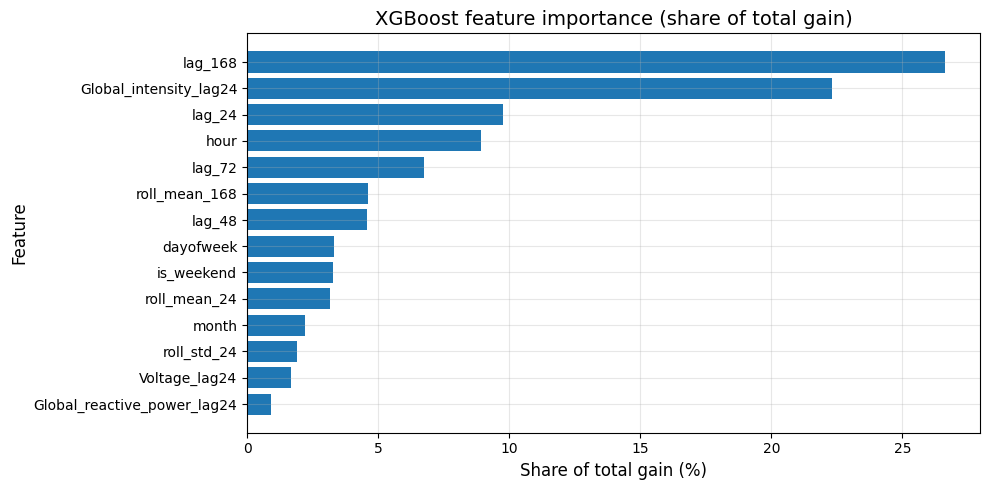

Top 5 features:
lag_168                   26.6
Global_intensity_lag24    22.3
lag_24                     9.7
hour                       8.9
lag_72                     6.8


In [103]:
# Feature importance (gain) for the full model: how much each feature reduces error
full_label = list(xgb_models)[-1]
full_model, full_cols = xgb_models[full_label]

importance = (pd.Series(full_model.get_booster().get_score(importance_type="gain"))
              .reindex(full_cols).fillna(0).sort_values())
importance = importance / importance.sum() * 100   # as % of total gain

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(importance.index, importance.values)
ax.set_title("XGBoost feature importance (share of total gain)")
ax.set_xlabel("Share of total gain (%)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

print("Top 5 features:")
print(importance.sort_values(ascending=False).head().round(1).to_string())

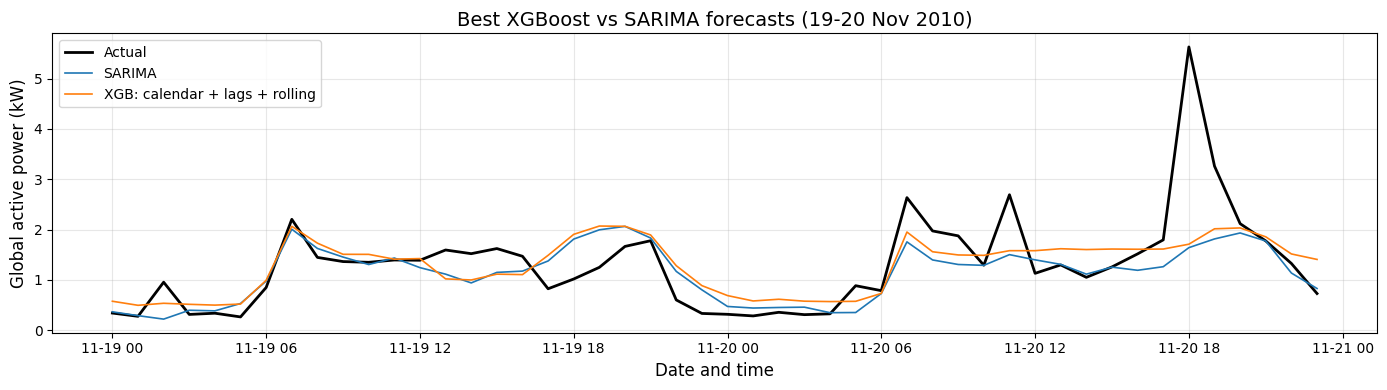

Best XGBoost model: XGB: calendar + lags + rolling


In [104]:
# Compare the best XGBoost model with SARIMA on the same two days as before
best_xgb_label = xgb_metrics.loc[xgb_metrics.Model.str.startswith("XGB"), "Model"].iloc[0]
zoom = xgb_compare.loc["2010-11-19":"2010-11-20"]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(zoom.index, zoom["Actual"], color="black", linewidth=2, label="Actual")
ax.plot(zoom.index, zoom["SARIMA"], linewidth=1.2, label="SARIMA")
ax.plot(zoom.index, zoom[best_xgb_label], linewidth=1.2, label=best_xgb_label)
ax.set_title("Best XGBoost vs SARIMA forecasts (19-20 Nov 2010)")
ax.set_xlabel("Date and time")
ax.set_ylabel("Global active power (kW)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print("Best XGBoost model:", best_xgb_label)

In [105]:
# Save forecasts, metrics and feature importance for the final comparison
xgb_compare.to_csv("results/xgb_forecasts.csv")
xgb_metrics.to_csv("results/xgb_metrics.csv", index=False)
importance.sort_values(ascending=False).to_csv("results/xgb_feature_importance.csv",
                                               header=["gain_percent"])
print("Saved results/xgb_forecasts.csv, xgb_metrics.csv and xgb_feature_importance.csv")

Saved results/xgb_forecasts.csv, xgb_metrics.csv and xgb_feature_importance.csv


## Step 13: Time-series foundation model – Chronos (Part 7)
Chronos-Bolt (Ansari et al., 2024) is a pre-trained transformer forecasting model.
It is used zero-shot: no training on this dataset. For each test day it receives
the previous 2048 hours (~85 days) of demand and forecasts the next 24 hours.
It outputs quantiles; the median is the point forecast and the 10%-90% quantiles
give an 80% prediction interval.

In [106]:
# Install the Chronos package (only needed once per Colab session, ~1 minute)
!pip install -q chronos-forecasting

import importlib.metadata
print("chronos-forecasting version:", importlib.metadata.version("chronos-forecasting"))

chronos-forecasting version: 2.3.2


In [107]:
# Download and load Chronos-Bolt (small) to run on the CPU
import torch
from chronos import BaseChronosPipeline

chronos = BaseChronosPipeline.from_pretrained(
    "amazon/chronos-bolt-small",
    device_map="cpu",
    torch_dtype=torch.float32,
)
print("Chronos-Bolt (small) loaded")

config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  191MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Chronos-Bolt (small) loaded


In [108]:
# For each test day, give Chronos the previous 2048 hours and ask for 24 hours ahead
CONTEXT_HOURS = 2048
contexts = [
    torch.tensor(series.loc[:day - pd.Timedelta(hours=1)].values[-CONTEXT_HOURS:],
                 dtype=torch.float32)
    for day in test_days
]

start = time.time()
quantiles, _ = chronos.predict_quantiles(contexts, prediction_length=HORIZON,
                                         quantile_levels=[0.1, 0.5, 0.9])
q = np.asarray(quantiles).reshape(-1, 3)          # (14 days x 24 h, 3 quantiles)

chronos_fc = pd.DataFrame({"Actual": test[TARGET].values,
                           "Chronos": q[:, 1],
                           "lower_80": q[:, 0],
                           "upper_80": q[:, 2]}, index=test.index)

print(f"Chronos forecasts: {len(chronos_fc)} hours in {time.time() - start:.1f} s")

Chronos forecasts: 336 hours in 1.6 s


In [109]:
# Compare Chronos with SARIMA, the best XGBoost model and the strongest benchmark
chronos_compare = pd.DataFrame({
    "Actual": chronos_fc["Actual"],
    "Chronos-Bolt (zero-shot)": chronos_fc["Chronos"],
    "SARIMA": sarima_fc["SARIMA"],
    best_xgb_label: xgb_compare[best_xgb_label],
    "Seasonal naive (weekly)": bench_fc["Seasonal naive (weekly)"],
})
chronos_metrics = evaluate_models(chronos_compare, train_series=train[TARGET])
print(chronos_metrics.to_string(index=False))

# Coverage of the 80% interval (ideal: about 80%)
inside = ((chronos_fc["Actual"] >= chronos_fc["lower_80"]) &
          (chronos_fc["Actual"] <= chronos_fc["upper_80"])).mean() * 100
print(f"\nChronos 80% interval coverage: {inside:.1f}% of actual values")

                         Model  RMSE   MAE  MAPE (%)  MASE
                        SARIMA 0.632 0.445    60.986 0.697
XGB: calendar + lags + rolling 0.635 0.460    66.935 0.719
      Chronos-Bolt (zero-shot) 0.638 0.422    51.395 0.660
       Seasonal naive (weekly) 0.832 0.573    70.079 0.897

Chronos 80% interval coverage: 79.2% of actual values


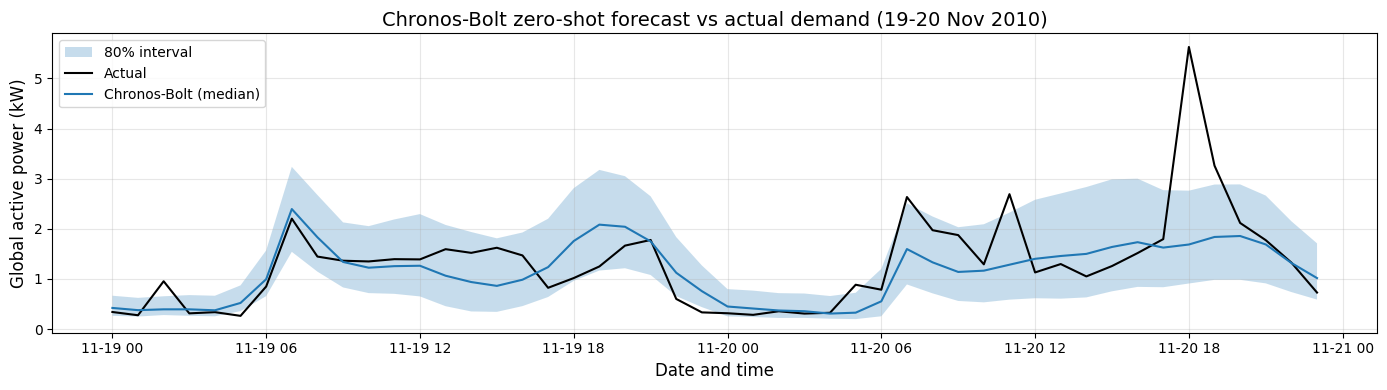

Lowest interval value: 0.11 kW (SARIMA went below 0)


In [110]:
# Chronos median forecast and 80% interval vs actual, same two days as before
zoom = chronos_fc.loc["2010-11-19":"2010-11-20"]

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(zoom.index, zoom["lower_80"], zoom["upper_80"], alpha=0.25, label="80% interval")
ax.plot(zoom.index, zoom["Actual"], color="black", linewidth=1.5, label="Actual")
ax.plot(zoom.index, zoom["Chronos"], linewidth=1.5, label="Chronos-Bolt (median)")
ax.set_title("Chronos-Bolt zero-shot forecast vs actual demand (19-20 Nov 2010)")
ax.set_xlabel("Date and time")
ax.set_ylabel("Global active power (kW)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Lowest interval value: {chronos_fc['lower_80'].min():.2f} kW (SARIMA went below 0)")

In [111]:
# Save forecasts and metrics for the final comparison
chronos_fc.to_csv("results/chronos_forecasts.csv")
chronos_metrics.to_csv("results/chronos_metrics.csv", index=False)
print("Saved results/chronos_forecasts.csv and results/chronos_metrics.csv")


Saved results/chronos_forecasts.csv and results/chronos_metrics.csv


## Step 14: Evaluation and comparison of all models (Part 8)
All models are compared on the same 14-day test period (12-25 Nov 2010) using
RMSE, MAE, MAPE and MASE, and against the strongest benchmark
(weekly seasonal naive). SARIMAX B is shown for reference only: it uses
future measured values and is therefore a conditional, not a true, forecast.

In [112]:
# One table with the actual values and every model's 336 hourly forecasts
all_fc = pd.DataFrame({"Actual": test[TARGET]})

for col in ["Mean", "Naive", "Drift", "Seasonal naive (daily)", "Seasonal naive (weekly)"]:
    all_fc[col] = bench_fc[col]
all_fc["SARIMA"] = sarima_fc["SARIMA"]
all_fc["SARIMAX A (weekend flag)"] = fc_cal["forecast"]
for label in xgb_models:
    all_fc[label] = xgb_fc[label]
all_fc["Chronos-Bolt (zero-shot)"] = chronos_fc["Chronos"]
all_fc["SARIMAX B (measured, conditional)"] = fc_meas["forecast"]

print(f"Combined forecasts: {all_fc.shape[1] - 1} models x {len(all_fc)} hours")

Combined forecasts: 13 models x 336 hours


In [113]:
# Score every model, add % improvement over the strongest benchmark, and flag true forecasts
final_metrics = evaluate_models(all_fc, train_series=train[TARGET])

bench_rmse = final_metrics.loc[final_metrics.Model == "Seasonal naive (weekly)", "RMSE"].item()
final_metrics["RMSE vs best benchmark (%)"] = ((bench_rmse - final_metrics["RMSE"])
                                               / bench_rmse * 100).round(1)
final_metrics["True forecast?"] = np.where(
    final_metrics.Model.str.contains("conditional"), "No (uses future data)", "Yes")

print(final_metrics.to_string(index=False))

                                             Model  RMSE   MAE  MAPE (%)  MASE  RMSE vs best benchmark (%)        True forecast?
                 SARIMAX B (measured, conditional) 0.028 0.017     1.875 0.026                        96.6 No (uses future data)
                                            SARIMA 0.632 0.445    60.986 0.697                        24.0                   Yes
                    XGB: calendar + lags + rolling 0.635 0.460    66.935 0.719                        23.7                   Yes
                              XGB: calendar + lags 0.635 0.462    67.704 0.722                        23.7                   Yes
XGB: calendar + lags + rolling + measured (lag 24) 0.636 0.464    68.031 0.725                        23.6                   Yes
                          SARIMAX A (weekend flag) 0.638 0.459    63.740 0.718                        23.3                   Yes
                          Chronos-Bolt (zero-shot) 0.638 0.422    51.395 0.660                   

In [123]:
# Add Bias (mean of forecast - actual) to the final table, as required by the module template
final_metrics["Bias"] = [round((all_fc[m] - all_fc["Actual"]).mean(), 3)
                         for m in final_metrics["Model"]]
print(final_metrics.to_string(index=False))

                                             Model  RMSE   MAE  MAPE (%)  MASE  RMSE vs best benchmark (%)        True forecast?   Bias
                 SARIMAX B (measured, conditional) 0.028 0.017     1.875 0.026                        96.6 No (uses future data)  0.001
                                            SARIMA 0.632 0.445    60.986 0.697                        24.0                   Yes -0.012
                    XGB: calendar + lags + rolling 0.635 0.460    66.935 0.719                        23.7                   Yes  0.071
                              XGB: calendar + lags 0.635 0.462    67.704 0.722                        23.7                   Yes  0.056
XGB: calendar + lags + rolling + measured (lag 24) 0.636 0.464    68.031 0.725                        23.6                   Yes  0.085
                          SARIMAX A (weekend flag) 0.638 0.459    63.740 0.718                        23.3                   Yes -0.017
                          Chronos-Bolt (zero-sho

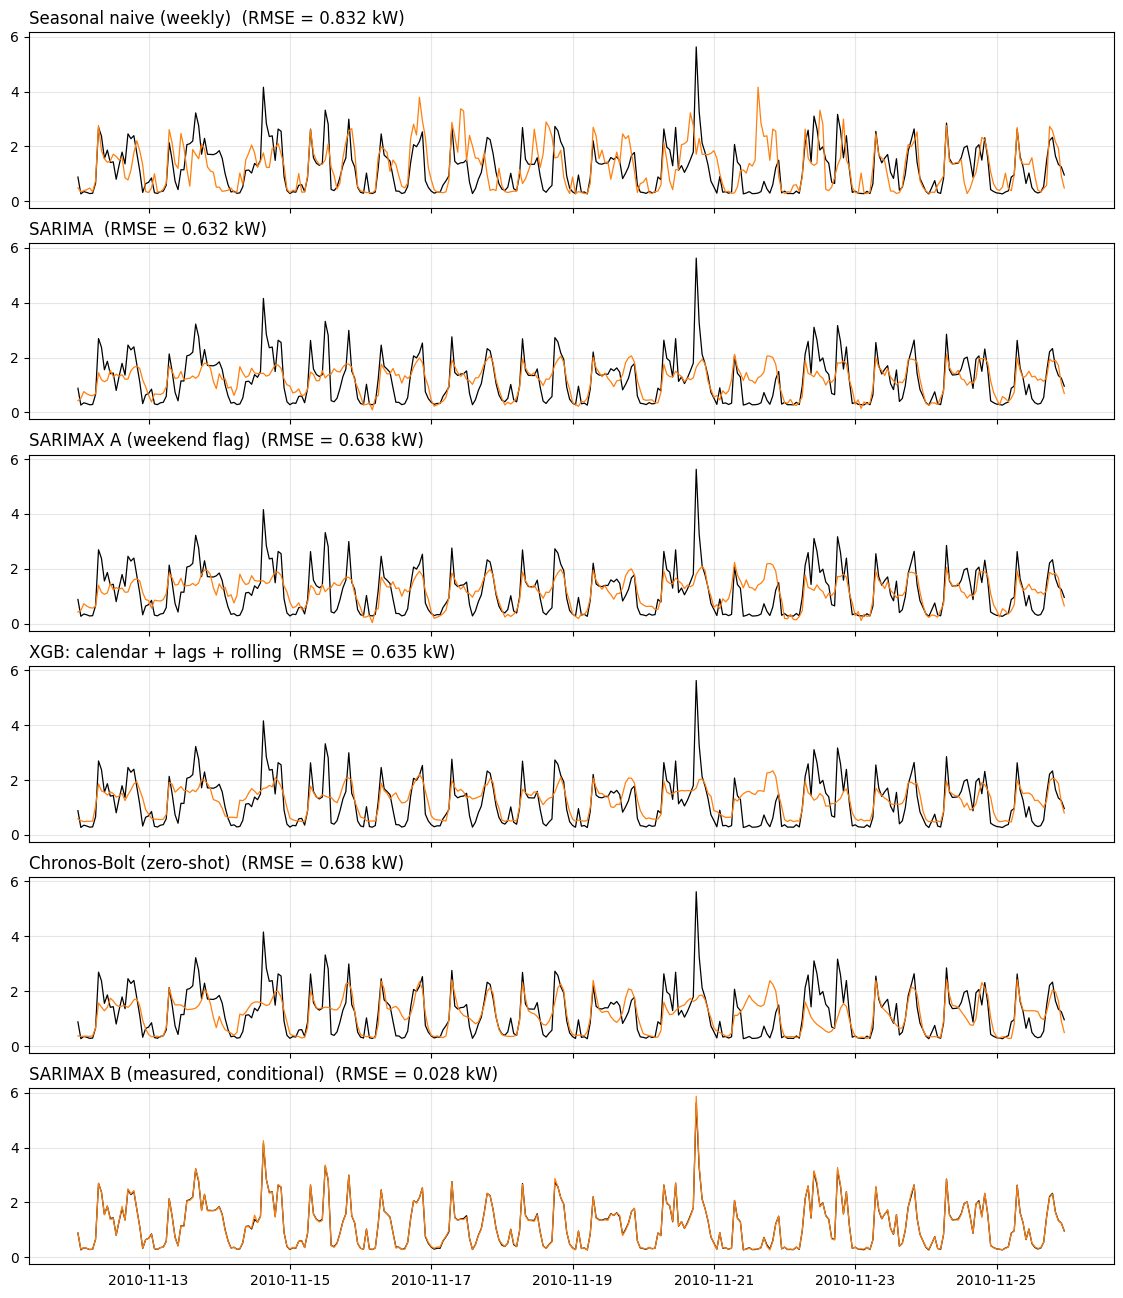

In [114]:
# One panel per key model across the full 14-day test period, same scale for fair comparison
models_to_plot = ["Seasonal naive (weekly)", "SARIMA", "SARIMAX A (weekend flag)",
                  best_xgb_label, "Chronos-Bolt (zero-shot)", "SARIMAX B (measured, conditional)"]

fig, axes = plt.subplots(len(models_to_plot), 1, figsize=(14, 16), sharex=True, sharey=True)
for ax, model in zip(axes, models_to_plot):
    score = final_metrics.loc[final_metrics.Model == model, "RMSE"].item()
    ax.plot(all_fc.index, all_fc["Actual"], color="black", linewidth=0.9, label="Actual")
    ax.plot(all_fc.index, all_fc[model], color="tab:orange", linewidth=0.9, label="Forecast")
    ax.set_title(f"{model}  (RMSE = {score:.3f} kW)", loc="left", fontsize=12)

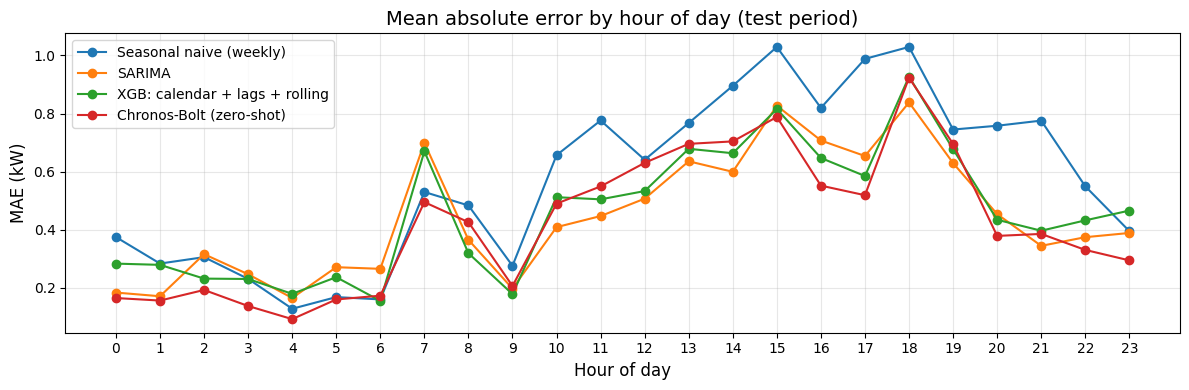

Hours with largest SARIMA error: [18, 15, 16]


In [115]:
# Mean absolute error for each hour of the day: when are the models most wrong?
key_models = ["Seasonal naive (weekly)", "SARIMA", best_xgb_label, "Chronos-Bolt (zero-shot)"]
errors = all_fc[key_models].sub(all_fc["Actual"], axis=0)
mae_by_hour = errors.abs().groupby(errors.index.hour).mean()

fig, ax = plt.subplots(figsize=(12, 4))
for model in key_models:
    ax.plot(mae_by_hour.index, mae_by_hour[model], marker="o", label=model)
ax.set_title("Mean absolute error by hour of day (test period)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("MAE (kW)")
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.show()

print("Hours with largest SARIMA error:",
      mae_by_hour["SARIMA"].sort_values(ascending=False).head(3).index.tolist())

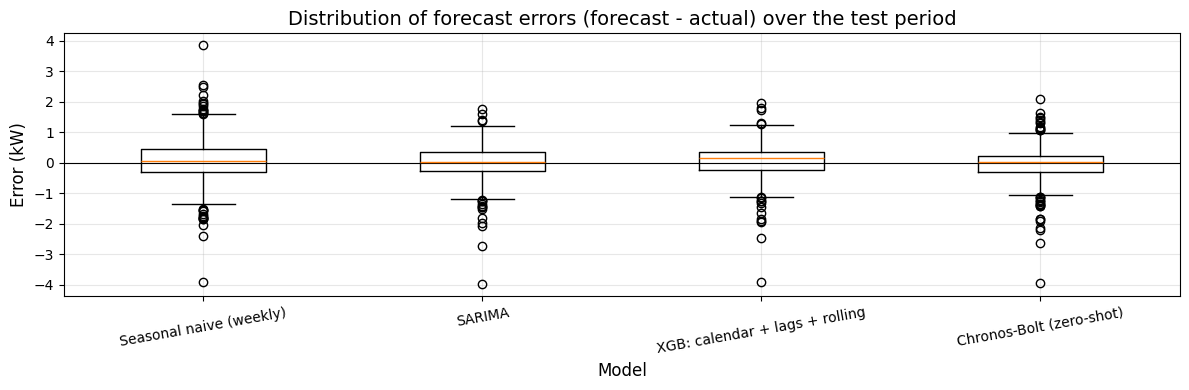

Mean error (bias, kW):
Seasonal naive (weekly)           0.063
SARIMA                           -0.012
XGB: calendar + lags + rolling    0.071
Chronos-Bolt (zero-shot)         -0.059


In [116]:
# Forecast errors (forecast - actual): negative = under-prediction
fig, ax = plt.subplots(figsize=(12, 4))
ax.boxplot([errors[m] for m in key_models], tick_labels=key_models, showfliers=True)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Distribution of forecast errors (forecast - actual) over the test period")
ax.set_xlabel("Model")
ax.set_ylabel("Error (kW)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

print("Mean error (bias, kW):")
print(errors.mean().round(3).to_string())

In [117]:
# Save the master metrics table and all forecasts (used for the report table)
final_metrics.to_csv("results/final_metrics_all_models.csv", index=False)
all_fc.to_csv("results/final_forecasts_all_models.csv")
mae_by_hour.to_csv("results/mae_by_hour.csv")

print("Saved: final_metrics_all_models.csv, final_forecasts_all_models.csv, mae_by_hour.csv")
print("All modelling steps (Parts 1-8) complete")

Saved: final_metrics_all_models.csv, final_forecasts_all_models.csv, mae_by_hour.csv
All modelling steps (Parts 1-8) complete
